# Guardrail effects in the coffee-shop simulations

This notebook answers two questions for the paper:

1. **Do guardrails have an effect** on how the multi-agent system behaves?
2. **If so, what kind of effect**, and does it differ between **soft** (LLM-judge) and **hard** (predicate) guardrails?

It starts with **simulation success**: did the customer actually get what the scenario asked for? Success is scored with scenario milestones, giving a strict all-or-nothing measure (Sections 3–6) and a graded progress score (Section 7). Section 8 then measures how cleanly the agents got there: failed tool calls and calls the guardrails blocked. Section 9 compares hard and soft enforcement on cost (conversation length, tokens) and on how often the gateway intervenes, and relates both to success. Section 9.5 sums up the general effect of guardrails against `flag` (success under both success definitions, token cost per success).

### Design

Two setup families, each in four enforcement variants. Within a family, all four variants have the same agents, prompts, guidelines and rules. They differ only in how the rules are enforced:

| Variant | Setups | Enforcement |
|---|---|---|
| `flag` | `baseline_flag`, `strict_flow_flag` | All rules are evaluated but never block. This is the **reference** condition. |
| `normal` | `baseline`, `strict_flow` | The class reference: a mix of hard and soft rules that block. |
| `soft` | `baseline_soft`, `strict_flow_soft` | Every rule is enforced by an LLM judge that blocks. The hard versions of those rules still run, flag-only, so judge and predicate verdicts can be compared on the same call. Exception: `strict_flow_soft` keeps the refund and machine-cleaning call limits as hard rules that block, because a counter has no sensible judge version. |
| `hard` | `baseline_hard`, `strict_flow_hard` | All rules are predicates that block. No LLM judges run. |

`flag` keeps every rule evaluating, so it is the right control: it shows what the agents do when nothing is enforced. Every other variant is compared against the `flag` variant of the **same family**.

### Contents

0. Configuration
1. Data
2. Success definition (milestones)
3. Reference: success rate in the `flag` setups
4. Effect of enforcement per scenario
5. Effect of enforcement pooled over scenarios
6. Soft vs hard
7. Progress score (partial success)
8. Failed and blocked calls
9. Hard vs soft: cost, interventions and success
10. Run-to-run consistency
11. Distribution figures
12. Next analyses

## 0. Configuration

The notebook reads the tables it needs from `SNAPSHOT_DIR`: Parquet files in the repository (`experiment_data/2026-11/analysis/`), extracted from the runs' MLflow stores. The stores themselves are several GB and are not in the repository.

`RUN_DIRS` lists those stores: the run folders copied from the simulation machine, each with an `mlflow.db` and an `experiment_runs/<run_id>/ledger.json`. They are only needed to rebuild the snapshot. To add a run, add its folder here, set `REBUILD_SNAPSHOT = True` and re-run the notebook.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd()
sys.path.insert(0, str(ANALYSIS_DIR))

import rate_stats as rs  # noqa: E402
from run_data import load_runs, load_snapshot, save_snapshot  # noqa: E402

SNAPSHOT_DIR = ANALYSIS_DIR.parent / "experiment_data" / "2026-11" / "analysis"
# Only needed with REBUILD_SNAPSHOT: the runs' MLflow stores, next to the repository.
REBUILD_SNAPSHOT = False
EXPERIMENT_RUNS = ANALYSIS_DIR.parent.parent / "experiment_runs"
RUN_DIRS = {
    "mini": EXPERIMENT_RUNS / "mini",
    "more": EXPERIMENT_RUNS / "more",
    "run3": EXPERIMENT_RUNS / "run3",
}

FAMILIES = ["baseline", "strict_flow"]
ENFORCEMENTS = ["flag", "normal", "soft", "hard"]
TREATMENTS = ["normal", "soft", "hard"]
SCENARIOS = {1: "S1 latte + croissant", 3: "S3 complaint", 4: "S4 recommendation"}
# pgfplots versions of selected figures, to \input into the paper.
FIGURES_DIR = ANALYSIS_DIR / "figures"

# Every figure names the success definition it uses (or that it doesn't use one).
LABEL_NEW = "success = new definition (all milestones)"
LABEL_OLD = "success = old definition (anything delivered)"
LABEL_NONE = "independent of the success definition"

# Reference gray for `flag`, then the first three categorical slots.
COLORS = {"flag": "#8a8984", "normal": "#2a78d6", "soft": "#eb6834", "hard": "#1baf7a"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": MUTED,
        "axes.titlecolor": INK,
        "axes.titlesize": 10,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "legend.frameon": False,
        "font.size": 9,
    }
)
pd.options.display.float_format = "{:.3f}".format

## 1. Data

### 1.1 Runs

Only runs made with the same code, model and machine seed should be pooled. Check that the `commit`, `model` and `machine_seed` columns agree.

In [2]:
if REBUILD_SNAPSHOT:
    save_snapshot(load_runs(RUN_DIRS), SNAPSHOT_DIR)
runs, conversations, tool_calls, gateway, llm_calls = load_snapshot(SNAPSHOT_DIR)
runs

,run,run_id,commit,model,machine_seed,setups,scenarios,per_cell,cells_done,cells
0,mini,20261028-155640,aca2f36,ollama:ministral-3:14b,100,8,"[1, 3, 4]",9,24,24
1,more,20261029-185412,aca2f36,ollama:ministral-3:14b,100,8,"[1, 3, 4]",16,24,24
2,run3,20261106-095238,aca2f36,ollama:ministral-3:14b,100,8,"[1, 3, 4]",25,24,24


In [3]:
assert (
    runs.commit.nunique() == 1
    and runs.model.nunique() == 1
    and runs.machine_seed.nunique() == 1
), "runs differ in code, model or machine seed; compare them instead of pooling"
assert (runs.cells_done == runs.cells).all(), "a run has unfinished cells"

### 1.2 Conversations per cell

One conversation is one MLflow session, tagged with its setup and scenario. Every setup × scenario cell should hold `per_cell` conversations from each run.

In [4]:
cell_counts = conversations.pivot_table(
    index=["family", "enforcement"],
    columns=["scenario", "run"],
    values="thread_id",
    aggfunc="count",
).reindex(pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS]))
expected = runs.set_index("run").per_cell
assert all(
    (cell_counts.xs(r, axis=1, level="run") == n).all().all()
    for r, n in expected.items()
), "missing conversations"
cell_counts

scenario              1              3              4          
run                mini more run3 mini more run3 mini more run3
baseline    flag      9   16   25    9   16   25    9   16   25
            normal    9   16   25    9   16   25    9   16   25
            soft      9   16   25    9   16   25    9   16   25
            hard      9   16   25    9   16   25    9   16   25
strict_flow flag      9   16   25    9   16   25    9   16   25
            normal    9   16   25    9   16   25    9   16   25
            soft      9   16   25    9   16   25    9   16   25
            hard      9   16   25    9   16   25    9   16   25

### 1.3 Tool calls, gateway decisions and LLM calls

`tool_calls` has one row per tool call that actually **ran**. Calls a guardrail denied never reach the tool, so they are not in it. `result` is the tool's return value parsed as JSON, and `result_text` is the raw text, used for error strings.

`gateway` has one row per call the gateway checked, with its decision (`allow`, `flag` or `deny`) and the rules that flagged or denied it (`violations`, with each rule's type). Denied calls are only visible here. `assistant_message` is the response gateway, which checks agent messages before the customer sees them.

`llm_calls` has one row per LLM call inside a conversation, with its token usage. `role` is `agent` for the agents' own calls and `judge` for soft-guardrail judges. Judges also run in the `flag` setups: they evaluate but never block. The customer simulator and the feedback call run outside the conversation's traces and are not included.

In [5]:
tool_calls.groupby("tool").size().sort_values(ascending=False).to_frame("calls").T

tool,place_on_tray,transfer_to_agent,process_order,get_order,start_preparation,end_preparation,update_stock,check_inventory,estimate_prep_time,check_tray,clean_machine,offer_refund,offer_partial_refund,get_alternatives,calculate_total
calls,2342,2299,1455,1122,960,926,851,836,406,218,128,20,18,11,7


In [6]:
gateway[gateway.event_type == "gateway_decision"].pivot_table(
    index="tool", columns="decision", values="thread_id", aggfunc="count", fill_value=0
)

decision,allow,deny,flag
tool,,,
assistant_message,6196,1188,786
calculate_total,7,1,0
check_inventory,834,19,3
check_tray,220,0,0
clean_machine,129,56,3
end_preparation,926,42,2
estimate_prep_time,430,0,0
get_alternatives,11,0,0
get_order,1126,0,0


In [7]:
llm_calls.merge(conversations[["thread_id", "setup"]], on="thread_id").pivot_table(
    index="setup",
    columns="role",
    values="total_tokens",
    aggfunc=["count", "sum"],
    fill_value=0,
)

count            sum         
role             agent judge    agent    judge
setup                                         
baseline          2726  1935  5140673  1422261
baseline_flag     2177  1718  3585204  1217342
baseline_hard     2431     0  4019607        0
baseline_soft     2831  3717  5125646  2043166
strict_flow       2569  1863  4731630  1276321
strict_flow_flag  2142  1861  3422656  1256418
strict_flow_hard  2340     0  4042204        0
strict_flow_soft  2700  3853  5082925  1931839

## 2. Success definition (milestones)

Success is judged from what the system actually **did** (executed tool calls), not from what the agents said or from the customer's feedback score. Each scenario has a few **milestones** on the way to the customer's goal:

| Scenario | Customer goal | Milestones |
|---|---|---|
| S1 | a large latte and a croissant | (1) an order went through · (2) a latte from it is on the tray · (3) a croissant from it is on the tray |
| S3 | complaint about a cold cappuccino | (1) a remedy was started: a refund, or a replacement order went through · (2) the remedy was completed: a refund, or an item of the replacement is on the tray |
| S4 | a recommendation, then order it | (1) an order went through · (2) the **first** order attempt went through, i.e. the drink the customer agreed to was really on the menu · (3) an item from the order is on the tray |

Two measures come from these milestones:

- **`success`** (Sections 3–6): every milestone was reached. This is the strict, all-or-nothing measure.
- **`progress`** (Section 7): the share of milestones reached, from 0 to 1. A milestone that was never attempted counts as not reached, so every conversation is scored.

What counts as successful:

- **Order:** `process_order` returned an `order_id`. Off-menu items and unknown extras return an error.
- **Tray:** `place_on_tray` returned `status: success`, **and** the item belongs to an order that went through in the same conversation. Unknown item names (for example `"large latte"`) return an error.
- **Refund:** `offer_refund` or `offer_partial_refund` returned a refund record (`refund_amount`). Unknown order ids return an error.

**Why S4 has milestone (2).** Without enforcement, the agents often recommend drinks that don't exist. The customer agrees, `process_order` rejects the order, and the agent talks the customer down to a plain menu item. The earlier definition ("anything on the tray") counted that as success. Milestone (2) fails it. It also fails a conversation whose first order broke for an unrelated reason, such as an unknown extra. The old definition is kept as `success_v1` for comparison.

**Blocked attempts count too.** In the enforcing setups an off-menu order is usually blocked by the gateway (`process_order:items_on_menu`) and never runs, so it is missing from `tool_calls`. Milestone (2) therefore uses the first order **attempt**, whether it ran or was blocked. Without this, a blocked off-menu order would be invisible in the enforcing setups, while the same order fails visibly in `flag`. That would make the comparison unfair.

**Refunds in S3.** The cold cappuccino has no order record, so a refund can only pay out on some other order. The table below shows whether each successful refund was for an order created in the same conversation. Refunds count as success as specified, but in this data every S3 refund was for an order from another conversation.

In [8]:
ORDER_TOOL, TRAY_TOOL = "process_order", "place_on_tray"
REFUND_TOOLS = ["offer_refund", "offer_partial_refund"]


def _call_ok(tool, r):
    if tool == ORDER_TOOL:
        return isinstance(r, dict) and "order_id" in r
    if tool == TRAY_TOOL:
        return isinstance(r, dict) and r.get("status") == "success"
    if tool in REFUND_TOOLS:
        return isinstance(r, dict) and "refund_amount" in r
    return None


calls = tool_calls.copy()
calls["ok"] = [_call_ok(t, r) for t, r in zip(calls.tool, calls.result)]
calls["item"] = calls.inputs.map(lambda i: str(i.get("item_name", "")).strip().lower())
calls["order_id"] = [
    (r.get("order_id") if t == ORDER_TOOL and ok else i.get("order_id"))
    for t, r, i, ok in zip(calls.tool, calls.result, calls.inputs, calls.ok)
]

# Orders that went through, with their item names; tray items must belong to one of them.
orders = calls[(calls.tool == ORDER_TOOL) & calls.ok]
order_items = {
    (t, o): {str(x.get("name", "")).strip().lower() for x in (i.get("order") or [])}
    for t, o, i in zip(orders.thread_id, orders.order_id, orders.inputs)
}
tray = calls[(calls.tool == TRAY_TOOL) & calls.ok].copy()
tray["in_order"] = [
    item in order_items.get((t, o), set())
    for t, o, item in zip(tray.thread_id, tray.order_id, tray.item)
]
tray_valid = tray[tray.in_order]
# First order *attempt*, including attempts the gateway blocked. A blocked call never ran,
# so it is only in `gateway`; it counts as not going through, the same as an order the
# tool rejected in `flag`. Gateway timestamps and span start times share the wall clock.
order_attempts = pd.concat(
    [
        calls.loc[calls.tool == ORDER_TOOL, ["thread_id", "ok"]].assign(
            t=calls.start_ns / 1e9
        ),
        gateway.loc[
            (gateway.event_type == "gateway_decision")
            & (gateway.tool == ORDER_TOOL)
            & (gateway.decision == "deny"),
            ["thread_id", "ts"],
        ]
        .rename(columns={"ts": "t"})
        .assign(ok=False),
    ]
).sort_values(["thread_id", "t"])
first_order_ok = order_attempts.groupby("thread_id").ok.first()

per_thread = pd.DataFrame(
    index=pd.Index(conversations.thread_id.unique(), name="thread_id")
)
per_thread["order_ok"] = per_thread.index.isin(orders.thread_id)
per_thread["first_order_ok"] = (
    per_thread.index.map(first_order_ok).fillna(False).astype(bool)
)
per_thread["tray_any"] = per_thread.index.isin(tray_valid.thread_id)
per_thread["tray_latte"] = per_thread.index.isin(
    tray_valid[tray_valid.item == "latte"].thread_id
)
per_thread["tray_croissant"] = per_thread.index.isin(
    tray_valid[tray_valid.item == "croissant"].thread_id
)
per_thread["refund"] = per_thread.index.isin(
    calls[calls.tool.isin(REFUND_TOOLS) & calls.ok].thread_id
)
# Earlier definition: any successful tray placement, without checking it against an order.
per_thread["tray_any_v1"] = per_thread.index.isin(tray.thread_id)
per_thread["tray_latte_v1"] = per_thread.index.isin(
    tray[tray.item == "latte"].thread_id
)
per_thread["tray_croissant_v1"] = per_thread.index.isin(
    tray[tray.item == "croissant"].thread_id
)

MILESTONES = {
    1: {
        "order went through": lambda d: d.order_ok,
        "latte on tray": lambda d: d.tray_latte,
        "croissant on tray": lambda d: d.tray_croissant,
    },
    3: {
        "remedy started": lambda d: d.refund | d.order_ok,
        "remedy completed": lambda d: d.refund | d.tray_any,
    },
    4: {
        "order went through": lambda d: d.order_ok,
        "first order went through": lambda d: d.first_order_ok,
        "item on tray": lambda d: d.tray_any,
    },
}
SUCCESS_V1 = {
    1: lambda d: d.tray_latte_v1 & d.tray_croissant_v1,
    3: lambda d: d.tray_any_v1 | d.refund,
    4: lambda d: d.tray_any_v1,
}

conv = conversations.join(per_thread, on="thread_id")
reached = []
for scenario, milestones in MILESTONES.items():
    d = conv[conv.scenario == scenario]
    for step, (name, rule) in enumerate(milestones.items(), start=1):
        reached.append(
            pd.DataFrame(
                {
                    "thread_id": d.thread_id,
                    "step": step,
                    "milestone": name,
                    "reached": rule(d).to_numpy(),
                }
            )
        )
milestones = pd.concat(reached, ignore_index=True).merge(
    conv[["thread_id", "run", "family", "enforcement", "scenario"]], on="thread_id"
)
by_thread = milestones.groupby("thread_id").reached
conv["progress"] = conv.thread_id.map(by_thread.mean())
conv["success"] = conv.thread_id.map(by_thread.all()).astype(bool)
conv["success_v1"] = False
for scenario, rule in SUCCESS_V1.items():
    mask = conv.scenario == scenario
    conv.loc[mask, "success_v1"] = rule(conv[mask])
conv["success_v1"] = conv.success_v1.astype(bool)

In [9]:
refunds = calls[calls.tool.isin(REFUND_TOOLS) & calls.ok]
own_orders = set(zip(orders.thread_id, orders.order_id))
refunds.assign(
    own_order=[
        (t, i.get("order_id")) in own_orders
        for t, i in zip(refunds.thread_id, refunds.inputs)
    ]
).merge(conv[["thread_id", "setup", "scenario"]], on="thread_id").groupby(
    ["scenario", "own_order"]
).size().to_frame("successful refunds")

,,successful refunds
scenario,own_order,
1,True,8
3,False,11
4,True,2


**Sanity check.** The share of conversations that reached each milestone, per scenario and variant, pooled over families and runs.

In [10]:
milestones.pivot_table(
    index=["scenario", "step", "milestone"],
    columns="enforcement",
    values="reached",
    aggfunc="mean",
)[ENFORCEMENTS]

enforcement                             flag  normal  soft  hard
scenario step milestone                                         
1        1    order went through       1.000   1.000 1.000 1.000
         2    latte on tray            0.830   0.830 0.640 0.690
         3    croissant on tray        0.790   0.860 0.770 0.810
3        1    remedy started           0.360   0.570 0.590 0.400
         2    remedy completed         0.240   0.280 0.330 0.250
4        1    order went through       1.000   1.000 1.000 1.000
         2    first order went through 0.000   0.700 0.680 0.770
         3    item on tray             0.770   0.660 0.730 0.790

In [11]:
s3 = conv[conv.scenario == 3]
pd.crosstab(
    [s3.family, s3.enforcement],
    pd.Categorical(
        np.select(
            [s3.tray_any & s3.refund, s3.tray_any, s3.refund],
            ["replacement + refund", "replacement only", "refund only"],
            "none",
        ),
        categories=["replacement only", "refund only", "replacement + refund", "none"],
    ),
    dropna=False,
).rename_axis(columns="S3 remedy completed via").reindex(
    pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS])
)

S3 remedy completed via  replacement only  refund only  replacement + refund  \
baseline    flag                       10            2                     0   
            normal                     17            0                     0   
            soft                       13            1                     0   
            hard                       11            2                     1   
strict_flow flag                       11            1                     0   
            normal                     11            0                     0   
            soft                       18            1                     0   
            hard                        8            3                     0   

S3 remedy completed via  none  
baseline    flag           38  
            normal         33  
            soft           36  
            hard           36  
strict_flow flag           38  
            normal         39  
            soft           31  
            hard           39

**Old vs new definition.** `success_v1` is the earlier definition (any successful tray placement, not checked against an order; for S4 no milestone 2). The new definition mainly changes S4 in the `flag` setups.

In [12]:
pd.concat(
    {
        "success_v1": conv.pivot_table(
            index=["family", "enforcement"], columns="scenario", values="success_v1"
        ),
        "success": conv.pivot_table(
            index=["family", "enforcement"], columns="scenario", values="success"
        ),
    },
    axis=1,
).reindex(pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS]))

success_v1             success            
scenario                    1     3     4       1     3     4
baseline    flag        0.740 0.260 0.860   0.740 0.240 0.000
            normal      0.880 0.340 0.780   0.880 0.340 0.500
            soft        0.640 0.300 0.800   0.620 0.280 0.540
            hard        0.700 0.280 0.860   0.700 0.280 0.660
strict_flow flag        0.560 0.240 0.680   0.560 0.240 0.000
            normal      0.680 0.220 0.600   0.680 0.220 0.440
            soft        0.500 0.400 0.720   0.500 0.380 0.420
            hard        0.600 0.220 0.740   0.600 0.220 0.520

### Helpers for the following sections

`rates()` counts successes per group and adds a Wilson 95% interval. `vs_reference()` compares one variant against another within the same family, cell by cell: risk difference, Newcombe 95% interval and Fisher's exact test. `pooled_vs_reference()` pools over strata (scenario × run, plus family where stated) with the Mantel-Haenszel risk difference and the CMH test.

`means()`, `means_vs_reference()` and `pooled_means_vs_reference()` do the same for numeric per-conversation measures (the progress score, call counts). They use Welch's t-test per cell, and a stratified mean difference with Mantel-Haenszel weights for pooling.

In [13]:
def rates(df, by):
    g = df.groupby(by).success.agg(k="sum", n="count").reset_index()
    g["rate"] = g.k / g.n
    g[["lo", "hi"]] = g.apply(lambda r: pd.Series(rs.wilson(r.k, r.n)), axis=1)
    return g


def vs_reference(df, treatments, reference="flag", by=("family", "scenario")):
    by = list(by)
    counts = rates(df, by + ["enforcement"]).set_index(by + ["enforcement"])
    rows = []
    for key, group in counts.groupby(level=by):
        ref = group.xs(reference, level="enforcement").iloc[0]
        for t in treatments:
            trt = group.xs(t, level="enforcement").iloc[0]
            d, lo, hi = rs.newcombe_diff(trt.k, trt.n, ref.k, ref.n)
            rows.append(
                {
                    **dict(zip(by, key if isinstance(key, tuple) else (key,))),
                    "enforcement": t,
                    "ref_rate": ref.rate,
                    "rate": trt.rate,
                    "diff": d,
                    "lo": lo,
                    "hi": hi,
                    "p": rs.fisher_p(trt.k, trt.n, ref.k, ref.n),
                    "n_ref": int(ref.n),
                    "n": int(trt.n),
                }
            )
    out = pd.DataFrame(rows)
    out["p_holm"] = rs.holm(out.p)
    return out


def pooled_vs_reference(
    df, treatments, reference="flag", groups=("family",), strata=("scenario", "run")
):
    groups, strata = list(groups), list(strata)
    counts = df.groupby(groups + strata + ["enforcement"]).success.agg(
        k="sum", n="count"
    )
    rows = []
    for t in treatments:
        grouped = (
            counts.groupby(level=groups[0] if len(groups) == 1 else groups)
            if groups
            else [((), counts)]
        )
        for key, g in grouped:
            wide = g.unstack("enforcement")
            table = pd.DataFrame(
                {
                    "k1": wide["k"][t],
                    "n1": wide["n"][t],
                    "k0": wide["k"][reference],
                    "n0": wide["n"][reference],
                }
            ).fillna(0)
            mh = rs.mantel_haenszel_rd(table)
            label = dict(zip(groups, key if isinstance(key, tuple) else (key,)))
            rows.append(
                {
                    **label,
                    "enforcement": t,
                    "vs": reference,
                    "rate": table.k1.sum() / table.n1.sum(),
                    "ref_rate": table.k0.sum() / table.n0.sum(),
                    **mh,
                    "n": int(table.n1.sum()),
                    "n_ref": int(table.n0.sum()),
                }
            )
    out = pd.DataFrame(rows)
    out["p_holm"] = rs.holm(out.p_cmh)
    return out


def ci_axes(ax, title=None):
    ax.set_ylim(-0.02, 1.02)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    if title:
        ax.set_title(title, loc="left")

In [14]:
def means(df, value, by):
    g = (
        df.groupby(by)[value]
        .apply(lambda x: pd.Series(rs.mean_ci(x), index=["mean", "lo", "hi"]))
        .unstack()
    )
    g["n"] = df.groupby(by)[value].count()
    return g.reset_index()


def means_vs_reference(
    df, value, treatments, reference="flag", by=("family", "scenario")
):
    rows = []
    for key, g in df.groupby(list(by)):
        x0 = g.loc[g.enforcement == reference, value]
        for t in treatments:
            x1 = g.loc[g.enforcement == t, value]
            d, lo, hi, p = rs.welch_diff(x1, x0)
            rows.append(
                {
                    **dict(zip(by, key)),
                    "enforcement": t,
                    "vs": reference,
                    "ref_mean": x0.mean(),
                    "mean": x1.mean(),
                    "diff": d,
                    "lo": lo,
                    "hi": hi,
                    "p": p,
                }
            )
    out = pd.DataFrame(rows)
    out["p_holm"] = rs.holm(out.p)
    return out


def pooled_means_vs_reference(
    df,
    value,
    treatments,
    reference="flag",
    groups=("family",),
    strata=("scenario", "run"),
):
    groups, strata = list(groups), list(strata)
    rows = []
    for t in treatments:
        for key, g in (
            df.groupby(groups[0] if len(groups) == 1 else groups)
            if groups
            else [((), df)]
        ):
            pairs = [
                (
                    s.loc[s.enforcement == t, value],
                    s.loc[s.enforcement == reference, value],
                )
                for _, s in g.groupby(strata)
            ]
            label = dict(zip(groups, key if isinstance(key, tuple) else (key,)))
            rows.append(
                {
                    **label,
                    "enforcement": t,
                    "vs": reference,
                    "mean": g.loc[g.enforcement == t, value].mean(),
                    "ref_mean": g.loc[g.enforcement == reference, value].mean(),
                    **rs.stratified_mean_diff(pairs),
                }
            )
    out = pd.DataFrame(rows)
    out["p_holm"] = rs.holm(out.p)
    return out

## 3. Reference: success rate in the `flag` setups

**Which success definition is used where.** Sections 3–7, 9.4 and 10 use the **new** definition (`success`, all milestones). Section 9.5 shows both side by side. Sections 8, 9.1–9.3 don't depend on a success definition. Every figure says which applies.

This shows what the agents achieve when every rule is evaluated but nothing is enforced, per family and scenario, pooled over runs. Intervals are Wilson 95%.

In [15]:
reference = conv[conv.enforcement == "flag"]
ref_rates = rates(reference, ["family", "scenario"])
ref_rates.pivot(
    index="scenario", columns="family", values=["k", "n", "rate", "lo", "hi"]
).rename(index=SCENARIOS)

k                    n                 rate  \
family               baseline strict_flow baseline strict_flow baseline   
scenario                                                                  
S1 latte + croissant   37.000      28.000   50.000      50.000    0.740   
S3 complaint           12.000      12.000   50.000      50.000    0.240   
S4 recommendation       0.000       0.000   50.000      50.000    0.000   

                                       lo                   hi              
family               strict_flow baseline strict_flow baseline strict_flow  
scenario                                                                    
S1 latte + croissant       0.560    0.604       0.423    0.841       0.688  
S3 complaint               0.240    0.143       0.143    0.374       0.374  
S4 recommendation          0.000    0.000       0.000    0.071       0.071

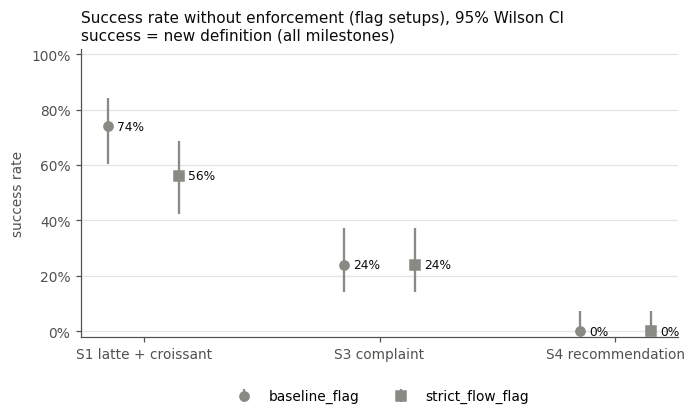

In [16]:
pooled_ref = rates(reference, ["scenario"]).assign(family="both families")
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(SCENARIOS))
offsets = {"baseline": -0.15, "strict_flow": 0.15}
markers = {"baseline": "o", "strict_flow": "s"}
for fam in FAMILIES:
    r = ref_rates[ref_rates.family == fam].set_index("scenario").loc[list(SCENARIOS)]
    ax.errorbar(
        x + offsets[fam],
        r.rate,
        yerr=[r.rate - r.lo, r.hi - r.rate],
        fmt=markers[fam],
        ms=6,
        color=COLORS["flag"],
        ecolor=COLORS["flag"],
        elinewidth=1.5,
        capsize=0,
        label=f"{fam}_flag",
    )
    for xi, v in zip(x + offsets[fam], r.rate):
        ax.annotate(
            f"{v:.0%}",
            (xi, v),
            xytext=(6, 0),
            textcoords="offset points",
            va="center",
            color=INK,
            fontsize=8,
        )
ax.set_xticks(x, SCENARIOS.values())
ci_axes(
    ax, f"Success rate without enforcement (flag setups), 95% Wilson CI\n{LABEL_NEW}"
)
ax.set_ylabel("success rate")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncols=2)
plt.show()

The same reference rates per run, as a first look at how stable a cell is between runs (Section 10 covers all setups).

In [17]:
rates(reference, ["family", "scenario", "run"]).pivot(
    index=["family", "scenario"], columns="run", values="rate"
).rename(index=SCENARIOS, level="scenario")

run                               mini  more  run3
family      scenario                              
baseline    S1 latte + croissant 0.778 0.688 0.760
            S3 complaint         0.444 0.125 0.240
            S4 recommendation    0.000 0.000 0.000
strict_flow S1 latte + croissant 0.778 0.500 0.520
            S3 complaint         0.222 0.188 0.280
            S4 recommendation    0.000 0.000 0.000

## 4. Effect of enforcement per scenario

Each enforcing variant (`normal`, `soft`, `hard`) is compared with the `flag` variant of the **same family and scenario**, pooled over runs.

- `diff` = rate − ref_rate, with a Newcombe 95% interval.
- `p` is Fisher's exact test (two-sided).
- `p_holm` corrects for the 18 comparisons in this table (Holm).

With 50 conversations per cell, only large effects will be significant here. Section 5 pools the scenarios for more power.

In [18]:
all_rates = rates(conv, ["family", "scenario", "enforcement"])
all_rates.pivot(
    index=["family", "enforcement"], columns="scenario", values="rate"
).reindex(pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS])).rename(
    columns=SCENARIOS
)

scenario            S1 latte + croissant  S3 complaint  S4 recommendation
baseline    flag                   0.740         0.240              0.000
            normal                 0.880         0.340              0.500
            soft                   0.620         0.280              0.540
            hard                   0.700         0.280              0.660
strict_flow flag                   0.560         0.240              0.000
            normal                 0.680         0.220              0.440
            soft                   0.500         0.380              0.420
            hard                   0.600         0.220              0.520

In [19]:
per_scenario = vs_reference(conv, TREATMENTS)
per_scenario.assign(scenario=per_scenario.scenario.map(SCENARIOS)).style.format(
    {c: "{:.0%}" for c in ["ref_rate", "rate"]}
    | {c: "{:+.0%}" for c in ["diff", "lo", "hi"]}
    | {"p": "{:.3f}", "p_holm": "{:.3f}"}
).hide(axis="index")

family,scenario,enforcement,ref_rate,rate,diff,lo,hi,p,n_ref,n,p_holm
baseline,S1 latte + croissant,normal,74%,88%,+14%,-2%,+29%,0.125,50,50,1.000
baseline,S1 latte + croissant,soft,74%,62%,-12%,-29%,+6%,0.284,50,50,1.000
baseline,S1 latte + croissant,hard,74%,70%,-4%,-21%,+13%,0.824,50,50,1.000
baseline,S3 complaint,normal,24%,34%,+10%,-8%,+27%,0.378,50,50,1.000
baseline,S3 complaint,soft,24%,28%,+4%,-13%,+21%,0.820,50,50,1.000
baseline,S3 complaint,hard,24%,28%,+4%,-13%,+21%,0.820,50,50,1.000
baseline,S4 recommendation,normal,0%,50%,+50%,+35%,+63%,0.000,50,50,0.000
baseline,S4 recommendation,soft,0%,54%,+54%,+39%,+67%,0.000,50,50,0.000
baseline,S4 recommendation,hard,0%,66%,+66%,+50%,+78%,0.000,50,50,0.000
strict_flow,S1 latte + croissant,normal,56%,68%,+12%,-7%,+30%,0.303,50,50,1.000


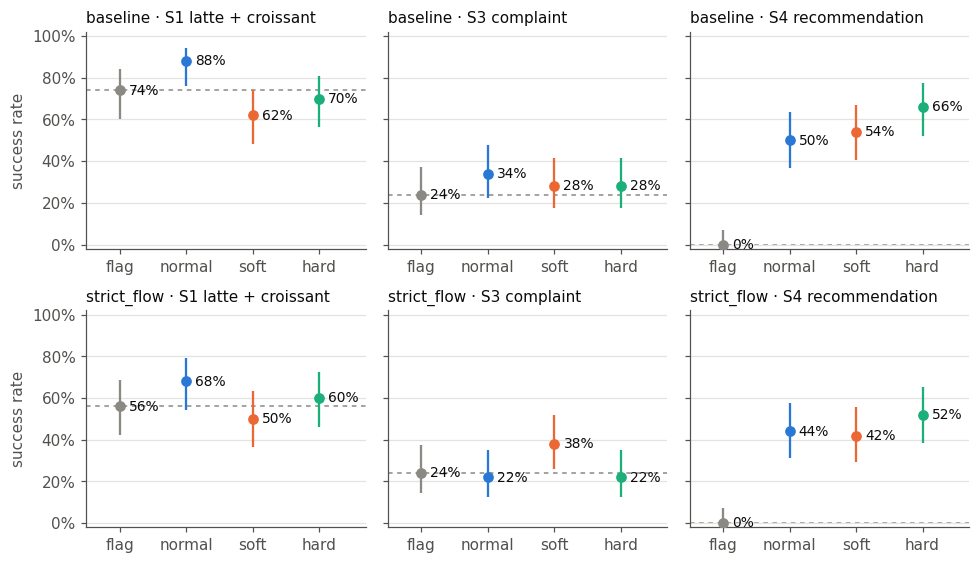

In [20]:
fig, axes = plt.subplots(len(FAMILIES), len(SCENARIOS), figsize=(9, 5.2), sharey=True)
for i, fam in enumerate(FAMILIES):
    for j, (scenario, label) in enumerate(SCENARIOS.items()):
        ax = axes[i, j]
        r = (
            all_rates[(all_rates.family == fam) & (all_rates.scenario == scenario)]
            .set_index("enforcement")
            .loc[ENFORCEMENTS]
        )
        ref_rate = r.loc["flag", "rate"]
        ax.axhline(ref_rate, color=COLORS["flag"], lw=1, ls=(0, (3, 3)), zorder=1)
        for k, e in enumerate(ENFORCEMENTS):
            ax.errorbar(
                k,
                r.loc[e, "rate"],
                yerr=[
                    [r.loc[e, "rate"] - r.loc[e, "lo"]],
                    [r.loc[e, "hi"] - r.loc[e, "rate"]],
                ],
                fmt="o",
                ms=6,
                color=COLORS[e],
                elinewidth=1.5,
                capsize=0,
                zorder=3,
            )
            ax.annotate(
                f"{r.loc[e, 'rate']:.0%}",
                (k, r.loc[e, "rate"]),
                xytext=(6, 0),
                textcoords="offset points",
                va="center",
                fontsize=9,
                color=INK,
            )
        ax.set_xticks(range(len(ENFORCEMENTS)), ENFORCEMENTS)
        ax.set_xlim(-0.5, len(ENFORCEMENTS) - 0.3)
        ci_axes(ax, f"{fam} · {label}")
    axes[i, 0].set_ylabel("success rate")
# fig.suptitle(
#     f"Success rate by enforcement variant (dashed: flag reference), 95% Wilson CI · {LABEL_NEW}",
#     x=0.01,
#     ha="left",
#     fontsize=10,
# )

# larger font size in graphics
for ax in axes.flat:
    ax.title.set_fontsize(10)
    ax.xaxis.label.set_fontsize(10)
    ax.yaxis.label.set_fontsize(10)
    ax.tick_params(axis="both", which="major", labelsize=10)

fig.tight_layout()
plt.show()

## 5. Effect of enforcement pooled over scenarios

The scenarios differ a lot in base rate, so simply pooling their conversations would mix those base rates together. Instead, the comparison is **stratified**: each scenario × run stratum compares a variant with `flag`, and the Mantel-Haenszel risk difference combines the strata.

- `rd` is the stratified difference in success rate (variant − flag), in percentage points, with a 95% interval (Sato variance).
- `p_cmh` is the Cochran-Mantel-Haenszel test.
- `p_holm` corrects within each table.

### 5.1 Per family

In [21]:
FMT_POOLED = (
    {c: "{:.0%}" for c in ["ref_rate", "rate"]}
    | {c: "{:+.0%}" for c in ["rd", "lo", "hi"]}
    | {"p_cmh": "{:.3f}", "p_holm": "{:.3f}"}
)
pooled_family = pooled_vs_reference(conv, TREATMENTS, groups=["family"])
pooled_family.style.format(FMT_POOLED).hide(axis="index")

family,enforcement,vs,rate,ref_rate,rd,lo,hi,p_cmh,strata,n,n_ref,p_holm
baseline,normal,flag,57%,33%,+25%,+15%,+34%,0.000,9,150,150,0.000
strict_flow,normal,flag,45%,27%,+18%,+8%,+28%,0.000,9,150,150,0.002
baseline,soft,flag,48%,33%,+15%,+5%,+26%,0.004,9,150,150,0.004
strict_flow,soft,flag,43%,27%,+17%,+6%,+27%,0.002,9,150,150,0.003
baseline,hard,flag,55%,33%,+22%,+11%,+33%,0.000,9,150,150,0.000
strict_flow,hard,flag,45%,27%,+18%,+8%,+28%,0.001,9,150,150,0.002


### 5.2 Both families (Question 1)

Here the strata are family × scenario × run, so each family is still compared only with its own `flag` setup. This is the most direct answer to *do guardrails have an effect on success?*, separately for each enforcement type.

In [22]:
pooled_all = pooled_vs_reference(
    conv, TREATMENTS, groups=[], strata=["family", "scenario", "run"]
)
pooled_all.style.format(FMT_POOLED).hide(axis="index")

enforcement,vs,rate,ref_rate,rd,lo,hi,p_cmh,strata,n,n_ref,p_holm
normal,flag,51%,30%,+21%,+15%,+28%,0.000,18,300,300,0.000
soft,flag,46%,30%,+16%,+9%,+23%,0.000,18,300,300,0.000
hard,flag,50%,30%,+20%,+13%,+27%,0.000,18,300,300,0.000


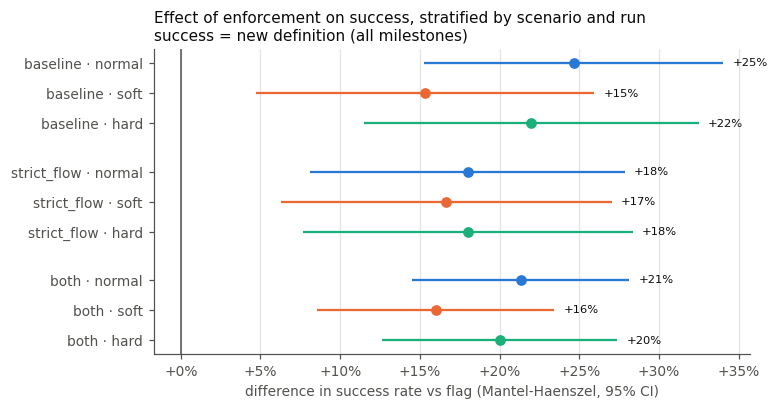

In [23]:
forest = pd.concat([pooled_family, pooled_all.assign(family="both")], ignore_index=True)
labels = ["baseline", "strict_flow", "both"]
fig, ax = plt.subplots(figsize=(7, 3.6))
y = 0
yticks, ylabels = [], []
for fam in labels:
    for e in TREATMENTS:
        r = forest[(forest.family == fam) & (forest.enforcement == e)].iloc[0]
        ax.errorbar(
            r.rd,
            y,
            xerr=[[r.rd - r.lo], [r.hi - r.rd]],
            fmt="o",
            ms=6,
            color=COLORS[e],
            elinewidth=1.5,
            capsize=0,
        )
        ax.annotate(
            f"{r.rd:+.0%}",
            (r.hi, y),
            xytext=(6, 0),
            textcoords="offset points",
            va="center",
            fontsize=7.5,
            color=INK,
        )
        yticks.append(y)
        ylabels.append(f"{fam} · {e}")
        y -= 1
    y -= 0.6
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(yticks, ylabels)
ax.grid(axis="x", color=GRID)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_xlabel("difference in success rate vs flag (Mantel-Haenszel, 95% CI)")
ax.set_title(
    f"Effect of enforcement on success, stratified by scenario and run\n{LABEL_NEW}",
    loc="left",
)
plt.show()

## 6. Soft vs hard (Question 2)

Sections 4 and 5 compare each variant with `flag`. This section compares the enforcing variants **with each other**, using the same stratification (scenario × run, plus family for the pooled row): `hard` vs `soft`, and `normal` (mixed) vs each pure variant.

In [24]:
pairs = [("hard", "soft"), ("normal", "soft"), ("normal", "hard")]
head_to_head = pd.concat(
    [
        pooled_vs_reference(conv, [t], reference=ref, groups=["family"])
        for t, ref in pairs
    ]
    + [
        pooled_vs_reference(
            conv, [t], reference=ref, groups=[], strata=["family", "scenario", "run"]
        ).assign(family="both")
        for t, ref in pairs
    ],
    ignore_index=True,
)
head_to_head["p_holm"] = rs.holm(head_to_head.p_cmh)
head_to_head[
    [
        "family",
        "enforcement",
        "vs",
        "rate",
        "ref_rate",
        "rd",
        "lo",
        "hi",
        "p_cmh",
        "p_holm",
        "n",
        "n_ref",
    ]
].style.format(FMT_POOLED).hide(axis="index")

family,enforcement,vs,rate,ref_rate,rd,lo,hi,p_cmh,p_holm,n,n_ref
baseline,hard,soft,55%,48%,+7%,-4%,+17%,0.223,1.000,150,150
strict_flow,hard,soft,45%,43%,+1%,-10%,+12%,0.812,1.000,150,150
baseline,normal,soft,57%,48%,+9%,-1%,+20%,0.087,0.779,150,150
strict_flow,normal,soft,45%,43%,+1%,-10%,+12%,0.810,1.000,150,150
baseline,normal,hard,57%,55%,+3%,-8%,+13%,0.615,1.000,150,150
strict_flow,normal,hard,45%,45%,+0%,-11%,+11%,1.000,1.000,150,150
both,hard,soft,50%,46%,+4%,-4%,+12%,0.307,1.000,300,300
both,normal,soft,51%,46%,+5%,-2%,+13%,0.170,1.000,300,300
both,normal,hard,51%,50%,+1%,-6%,+9%,0.724,1.000,300,300


Per scenario, `hard` vs `soft` within each family (Newcombe interval, Fisher test, Holm over the 6 comparisons):

In [25]:
hard_vs_soft = vs_reference(conv, ["hard"], reference="soft")
hard_vs_soft.assign(scenario=hard_vs_soft.scenario.map(SCENARIOS)).rename(
    columns={"ref_rate": "soft_rate", "rate": "hard_rate"}
).style.format(
    {c: "{:.0%}" for c in ["soft_rate", "hard_rate"]}
    | {c: "{:+.0%}" for c in ["diff", "lo", "hi"]}
    | {"p": "{:.3f}", "p_holm": "{:.3f}"}
).hide(axis="index")

family,scenario,enforcement,soft_rate,hard_rate,diff,lo,hi,p,n_ref,n,p_holm
baseline,S1 latte + croissant,hard,62%,70%,+8%,-10%,+26%,0.527,50,50,1.000
baseline,S3 complaint,hard,28%,28%,+0%,-17%,+17%,1.000,50,50,1.000
baseline,S4 recommendation,hard,54%,66%,+12%,-7%,+30%,0.307,50,50,1.000
strict_flow,S1 latte + croissant,hard,50%,60%,+10%,-9%,+28%,0.422,50,50,1.000
strict_flow,S3 complaint,hard,38%,22%,-16%,-33%,+2%,0.126,50,50,0.756
strict_flow,S4 recommendation,hard,42%,52%,+10%,-9%,+28%,0.423,50,50,1.000


## 7. Progress score (partial success)

`progress` is the share of a scenario's milestones a conversation reached (S1 and S4 have 3 milestones, S3 has 2). It separates "got nowhere" from "almost made it", which the all-or-nothing `success` hides. Mean progress per cell, with a normal-approximation 95% interval:

In [26]:
progress = means(conv, "progress", ["family", "scenario", "enforcement"])
progress.pivot(
    index=["family", "enforcement"], columns="scenario", values="mean"
).reindex(pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS])).rename(
    columns=SCENARIOS
)

scenario            S1 latte + croissant  S3 complaint  S4 recommendation
baseline    flag                   0.907         0.270              0.620
            normal                 0.947         0.460              0.813
            soft                   0.833         0.420              0.820
            hard                   0.840         0.330              0.887
strict_flow flag                   0.840         0.330              0.560
            normal                 0.847         0.390              0.760
            soft                   0.773         0.500              0.787
            hard                   0.827         0.320              0.820

Where do conversations stop? The deepest milestone reached in an unbroken run from the start (0 = not even the first one), per scenario and variant, pooled over families and runs:

In [27]:
depth = (
    milestones.sort_values("step")
    .groupby("thread_id")
    .reached.apply(lambda r: int(np.cumprod(r.to_numpy()).sum()))
    .rename("depth")
)
conv["depth"] = conv.thread_id.map(depth)
pd.crosstab([conv.scenario, conv.enforcement], conv.depth, normalize="index").reindex(
    pd.MultiIndex.from_product([list(SCENARIOS), ENFORCEMENTS])
).rename(index=SCENARIOS, level=0)

depth                           0     1     2     3
S1 latte + croissant flag   0.000 0.170 0.180 0.650
                     normal 0.000 0.170 0.050 0.780
                     soft   0.000 0.360 0.080 0.560
                     hard   0.000 0.310 0.040 0.650
S3 complaint         flag   0.640 0.120 0.240 0.000
                     normal 0.430 0.290 0.280 0.000
                     soft   0.410 0.260 0.330 0.000
                     hard   0.600 0.150 0.250 0.000
S4 recommendation    flag   0.000 1.000 0.000 0.000
                     normal 0.000 0.300 0.230 0.470
                     soft   0.000 0.320 0.200 0.480
                     hard   0.000 0.230 0.180 0.590

**Progress vs `flag`.** Per cell (Welch's t-test, Holm over the 18 comparisons), then pooled over scenario × run, per family and for both families together.

In [28]:
FMT_MEAN = (
    {c: "{:.2f}" for c in ["ref_mean", "mean"]}
    | {c: "{:+.2f}" for c in ["diff", "lo", "hi"]}
    | {"p": "{:.3f}", "p_holm": "{:.3f}"}
)
progress_cells = means_vs_reference(conv, "progress", TREATMENTS)
progress_cells.assign(scenario=progress_cells.scenario.map(SCENARIOS)).style.format(
    FMT_MEAN
).hide(axis="index")

family,scenario,enforcement,vs,ref_mean,mean,diff,lo,hi,p,p_holm
baseline,S1 latte + croissant,normal,flag,0.91,0.95,+0.04,-0.02,+0.10,0.217,1.000
baseline,S1 latte + croissant,soft,flag,0.91,0.83,-0.07,-0.15,+0.01,0.075,0.752
baseline,S1 latte + croissant,hard,flag,0.91,0.84,-0.07,-0.15,+0.02,0.133,1.000
baseline,S3 complaint,normal,flag,0.27,0.46,+0.19,+0.02,+0.36,0.031,0.375
baseline,S3 complaint,soft,flag,0.27,0.42,+0.15,-0.02,+0.32,0.081,0.752
baseline,S3 complaint,hard,flag,0.27,0.33,+0.06,-0.11,+0.23,0.496,1.000
baseline,S4 recommendation,normal,flag,0.62,0.81,+0.19,+0.13,+0.26,0.000,0.000
baseline,S4 recommendation,soft,flag,0.62,0.82,+0.20,+0.13,+0.27,0.000,0.000
baseline,S4 recommendation,hard,flag,0.62,0.89,+0.27,+0.21,+0.32,0.000,0.000
strict_flow,S1 latte + croissant,normal,flag,0.84,0.85,+0.01,-0.08,+0.09,0.880,1.000


In [29]:
progress_pooled = pd.concat(
    [
        pooled_means_vs_reference(conv, "progress", TREATMENTS, groups=["family"]),
        pooled_means_vs_reference(
            conv,
            "progress",
            TREATMENTS,
            groups=[],
            strata=["family", "scenario", "run"],
        ).assign(family="both"),
    ],
    ignore_index=True,
)
progress_pooled["p_holm"] = rs.holm(progress_pooled.p)
progress_pooled.style.format(FMT_MEAN).hide(axis="index")

family,enforcement,vs,mean,ref_mean,diff,lo,hi,p,strata,p_holm
baseline,normal,flag,0.74,0.60,+0.14,+0.08,+0.21,0.000,9,0.000
strict_flow,normal,flag,0.67,0.58,+0.09,+0.02,+0.15,0.008,9,0.023
baseline,soft,flag,0.69,0.60,+0.09,+0.03,+0.16,0.005,9,0.021
strict_flow,soft,flag,0.69,0.58,+0.11,+0.04,+0.18,0.002,9,0.008
baseline,hard,flag,0.69,0.60,+0.09,+0.02,+0.15,0.012,9,0.023
strict_flow,hard,flag,0.66,0.58,+0.08,+0.01,+0.15,0.021,9,0.023
both,normal,flag,0.70,0.59,+0.12,+0.07,+0.16,0.000,18,0.000
both,soft,flag,0.69,0.59,+0.10,+0.05,+0.15,0.000,18,0.000
both,hard,flag,0.67,0.59,+0.08,+0.04,+0.13,0.001,18,0.004


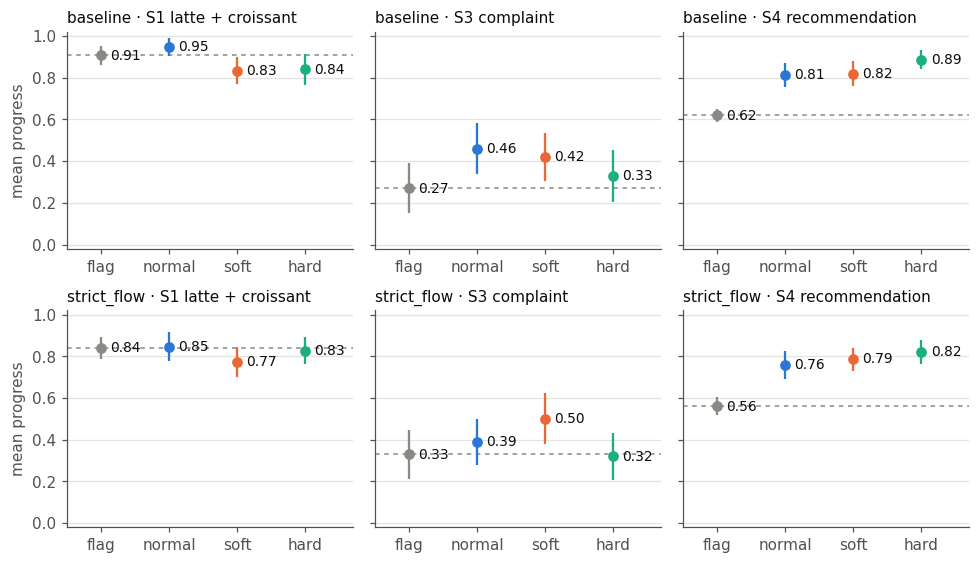

In [30]:
fig, axes = plt.subplots(len(FAMILIES), len(SCENARIOS), figsize=(9, 5.2), sharey=True)
for i, fam in enumerate(FAMILIES):
    for j, (scenario, label) in enumerate(SCENARIOS.items()):
        ax = axes[i, j]
        r = (
            progress[(progress.family == fam) & (progress.scenario == scenario)]
            .set_index("enforcement")
            .loc[ENFORCEMENTS]
        )
        ax.axhline(
            r.loc["flag", "mean"], color=COLORS["flag"], lw=1, ls=(0, (3, 3)), zorder=1
        )
        for k, e in enumerate(ENFORCEMENTS):
            m, lo, hi = r.loc[e, ["mean", "lo", "hi"]]
            ax.errorbar(
                k,
                m,
                yerr=[[m - lo], [hi - m]],
                fmt="o",
                ms=6,
                color=COLORS[e],
                elinewidth=1.5,
                capsize=0,
                zorder=3,
            )
            ax.annotate(
                f"{m:.2f}",
                (k, m),
                xytext=(6, 0),
                textcoords="offset points",
                va="center",
                fontsize=9,
                color=INK,
            )
        ax.set_xticks(range(len(ENFORCEMENTS)), ENFORCEMENTS)
        ax.set_xlim(-0.5, len(ENFORCEMENTS) - 0.3)
        ax.set_ylim(-0.02, 1.02)
        ax.set_title(f"{fam} · {label}", loc="left")
    axes[i, 0].set_ylabel("mean progress")
# fig.suptitle(
#     "Progress score by enforcement variant (dashed: flag reference), 95% CI · progress = share of the new definition's milestones",
#     x=0.01,
#     ha="left",
#     fontsize=10,
# )

# larger font size in graphics
for ax in axes.flat:
    ax.title.set_fontsize(10)
    ax.xaxis.label.set_fontsize(10)
    ax.yaxis.label.set_fontsize(10)
    ax.tick_params(axis="both", which="major", labelsize=10)

fig.tight_layout()
plt.show()

## 8. Failed and blocked calls

This section measures how cleanly the agents got where they did, separately from whether they got there. For the three goal-relevant tools it counts, per conversation:

- **failed:** the tool ran and returned an error (off-menu order, unknown tray item, unknown order id for a refund);
- **blocked:** the gateway denied the call, so it never ran. Only enforcing setups can block. In `flag` the same call runs, and fails or succeeds on its own.

`attempts lost` = failed + blocked: calls the agent made that did not go through. Comparing it with `flag` shows whether enforcement removes bad calls, or just moves them from "failed" to "blocked".

In [31]:
TOOL_GROUPS = {
    ORDER_TOOL: "order",
    TRAY_TOOL: "tray",
    **{t: "refund" for t in REFUND_TOOLS},
}

failed = calls[calls.tool.isin(TOOL_GROUPS) & (calls.ok == False)]  # noqa: E712
blocked = gateway[
    (gateway.event_type == "gateway_decision")
    & (gateway.decision == "deny")
    & gateway.tool.isin(TOOL_GROUPS)
]
for kind, df in {"failed": failed, "blocked": blocked}.items():
    counts = (
        df.assign(group=df.tool.map(TOOL_GROUPS))
        .groupby(["thread_id", "group"])
        .size()
        .unstack(fill_value=0)
    )
    for group in ["order", "tray", "refund"]:
        col = counts[group] if group in counts else pd.Series(dtype=int)
        conv[f"{kind}_{group}"] = conv.thread_id.map(col).fillna(0).astype(int)
for kind in ["failed", "blocked"]:
    conv[f"{kind}_calls"] = conv[
        [f"{kind}_order", f"{kind}_tray", f"{kind}_refund"]
    ].sum(axis=1)
conv["attempts_lost"] = conv.failed_calls + conv.blocked_calls

COUNT_COLS = [
    f"{k}_{g}" for g in ["order", "tray", "refund"] for k in ["failed", "blocked"]
] + ["attempts_lost"]
conv.groupby(["family", "enforcement"])[COUNT_COLS].mean().reindex(
    pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS])
)

failed_order  blocked_order  failed_tray  blocked_tray  \
baseline    flag           1.313          0.000        0.767         0.000   
            normal         0.047          0.160        1.407         0.000   
            soft           0.040          0.140        1.093         0.000   
            hard           0.067          0.080        0.967         0.000   
strict_flow flag           1.400          0.000        0.447         0.000   
            normal         0.053          0.173        1.040         0.000   
            soft           0.013          0.207        1.267         0.000   
            hard           0.027          0.160        0.853         0.000   

                    failed_refund  blocked_refund  attempts_lost  
baseline    flag            0.047           0.000          2.127  
            normal          0.013           0.120          1.747  
            soft            0.000           0.233          1.507  
            hard            0.020           0.213          1.347  
strict_flow flag            0.020           0.000          1.867  
            normal          0.007           0.053          1.327  
            soft            0.007           0.067          1.560  
            hard            0.000           0.033          1.073

The same per scenario (mean per conversation):

In [32]:
conv.groupby(["scenario", "family", "enforcement"])[COUNT_COLS].mean().reindex(
    pd.MultiIndex.from_product([list(SCENARIOS), FAMILIES, ENFORCEMENTS])
).rename(index=SCENARIOS, level=0)

failed_order  blocked_order  \
S1 latte + croissant baseline    flag           0.380          0.000   
                                 normal         0.060          0.040   
                                 soft           0.060          0.020   
                                 hard           0.120          0.020   
                     strict_flow flag           0.520          0.000   
                                 normal         0.140          0.020   
                                 soft           0.020          0.040   
                                 hard           0.020          0.040   
S3 complaint         baseline    flag           0.060          0.000   
                                 normal         0.040          0.080   
                                 soft           0.020          0.080   
                                 hard           0.020          0.040   
                     strict_flow flag           0.120          0.000   
                                 normal         0.020          0.140   
                                 soft           0.020          0.200   
                                 hard           0.000          0.100   
S4 recommendation    baseline    flag           3.500          0.000   
                                 normal         0.040          0.360   
                                 soft           0.040          0.320   
                                 hard           0.060          0.180   
                     strict_flow flag           3.560          0.000   
                                 normal         0.000          0.360   
                                 soft           0.000          0.380   
                                 hard           0.060          0.340   

                                         failed_tray  blocked_tray  \
S1 latte + croissant baseline    flag          0.960         0.000   
                                 normal        0.940         0.000   
                                 soft          0.660         0.000   
                                 hard          0.820         0.000   
                     strict_flow flag          0.480         0.000   
                                 normal        0.360         0.000   
                                 soft          0.800         0.000   
                                 hard          0.480         0.000   
S3 complaint         baseline    flag          0.240         0.000   
                                 normal        1.000         0.000   
                                 soft          0.740         0.000   
                                 hard          0.340         0.000   
                     strict_flow flag          0.320         0.000   
                                 normal        0.700         0.000   
                                 soft          0.840         0.000   
                                 hard          0.180         0.000   
S4 recommendation    baseline    flag          1.100         0.000   
                                 normal        2.280         0.000   
                                 soft          1.880         0.000   
                                 hard          1.740         0.000   
                     strict_flow flag          0.540         0.000   
                                 normal        2.060         0.000   
                                 soft          2.160         0.000   
                                 hard          1.900         0.000   

                                         failed_refund  blocked_refund  \
S1 latte + croissant baseline    flag            0.000           0.000   
                                 normal          0.000           0.000   
                                 soft            0.000           0.000   
                                 hard            0.000           0.140   
                     strict_flow flag            0.000           0.000   
                                 normal      

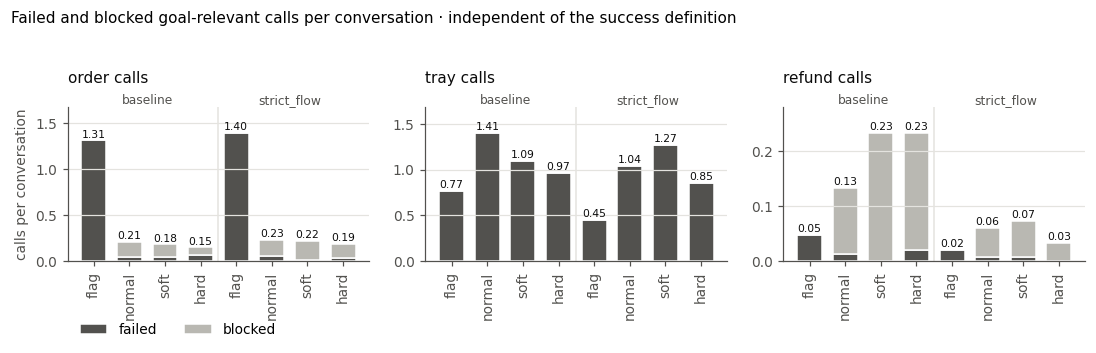

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=False)
SHADES = {"failed": "#52514e", "blocked": "#b9b8b2"}
for ax, group in zip(axes, ["order", "tray", "refund"]):
    m = (
        conv.groupby(["family", "enforcement"])[[f"failed_{group}", f"blocked_{group}"]]
        .mean()
        .reindex(pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS]))
    )
    x = np.arange(len(m))
    bottom = np.zeros(len(m))
    for kind in ["failed", "blocked"]:
        v = m[f"{kind}_{group}"].to_numpy()
        ax.bar(
            x,
            v,
            bottom=bottom,
            width=0.7,
            color=SHADES[kind],
            edgecolor="white",
            linewidth=1,
            label=kind,
        )
        bottom += v
    for xi, total in zip(x, bottom):
        ax.annotate(
            f"{total:.2f}",
            (xi, total),
            xytext=(0, 2),
            textcoords="offset points",
            ha="center",
            fontsize=7,
            color=INK,
        )
    ax.set_ylim(0, bottom.max() * 1.2)
    ax.set_xticks(x, [e for _ in FAMILIES for e in ENFORCEMENTS], rotation=90)
    ax.axvline(len(ENFORCEMENTS) - 0.5, color=GRID, lw=1)
    ax.set_title(f"{group} calls", loc="left", pad=16)
    for k, fam in enumerate(FAMILIES):
        ax.annotate(
            fam,
            (k * len(ENFORCEMENTS) + 1.5, 1.0),
            xycoords=("data", "axes fraction"),
            ha="center",
            va="bottom",
            fontsize=8,
            color=MUTED,
        )
axes[0].set_ylabel("calls per conversation")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.32), ncols=2)
fig.suptitle(
    f"Failed and blocked goal-relevant calls per conversation · {LABEL_NONE}",
    x=0.01,
    ha="left",
    fontsize=10,
    y=1.04,
)
fig.tight_layout()
plt.show()

**Attempts lost vs `flag`**, pooled over scenario × run (per family, then both families). A negative difference means fewer calls were lost than without enforcement.

In [34]:
lost_pooled = pd.concat(
    [
        pooled_means_vs_reference(conv, value, TREATMENTS, groups=["family"]).assign(
            measure=value
        )
        for value in ["failed_calls", "blocked_calls", "attempts_lost"]
    ]
    + [
        pooled_means_vs_reference(
            conv, value, TREATMENTS, groups=[], strata=["family", "scenario", "run"]
        ).assign(family="both", measure=value)
        for value in ["failed_calls", "blocked_calls", "attempts_lost"]
    ],
    ignore_index=True,
)
lost_pooled["p_holm"] = rs.holm(lost_pooled.p)
lost_pooled[
    [
        "measure",
        "family",
        "enforcement",
        "ref_mean",
        "mean",
        "diff",
        "lo",
        "hi",
        "p",
        "p_holm",
    ]
].style.format(FMT_MEAN).hide(axis="index")

measure,family,enforcement,ref_mean,mean,diff,lo,hi,p,p_holm
failed_calls,baseline,normal,2.13,1.47,-0.66,-0.97,-0.35,0.000,0.000
failed_calls,strict_flow,normal,1.87,1.10,-0.77,-1.05,-0.48,0.000,0.000
failed_calls,baseline,soft,2.13,1.13,-0.99,-1.30,-0.68,0.000,0.000
failed_calls,strict_flow,soft,1.87,1.29,-0.58,-0.90,-0.26,0.000,0.002
failed_calls,baseline,hard,2.13,1.05,-1.07,-1.34,-0.81,0.000,0.000
failed_calls,strict_flow,hard,1.87,0.88,-0.99,-1.24,-0.73,0.000,0.000
blocked_calls,baseline,normal,0.00,0.28,+0.28,+0.18,+0.38,0.000,0.000
blocked_calls,strict_flow,normal,0.00,0.23,+0.23,+0.15,+0.30,0.000,0.000
blocked_calls,baseline,soft,0.00,0.37,+0.37,+0.20,+0.55,0.000,0.000
blocked_calls,strict_flow,soft,0.00,0.27,+0.27,+0.18,+0.37,0.000,0.000


Failed tray placements by error message. Most are naming errors: the barista passes a description (`"large latte"`) instead of the menu name, then retries.

In [35]:
tray_errors = calls[(calls.tool == TRAY_TOOL) & (calls.ok == False)].copy()  # noqa: E712
tray_errors["message"] = tray_errors.result.map(
    lambda r: (r or {}).get("message", "unparseable")
)
tray_errors["kind"] = tray_errors.message.str.replace(
    r"^Unknown item: .*", "Unknown item", regex=True
).str.replace(r"order status is \w+", "order status is <status>", regex=True)
display(tray_errors.groupby("kind").size().to_frame("calls"))
tray_errors[tray_errors.kind == "Unknown item"].item.value_counts().head(10).to_frame(
    "calls (top 10 unknown names)"
)

,calls
kind,
Cannot place items — order status is <status>,89
Unknown item,1086
unparseable,1


,calls (top 10 unknown names)
item,
large latte,151
medium cappuccino,69
large cappuccino,37
medium vanilla cappuccino,35
medium americano,19
large hot cappuccino,19
blueberry muffin,18
vanilla cappuccino,17
large iced latte,16


## 9. Hard vs soft: cost, interventions and success

Section 6 found no difference in success between hard and soft enforcement. This section asks what each kind of enforcement **costs** and how often it **intervenes**, and how both relate to success:

- **Conversation length:** customer turns (one trace per customer message) and wall-clock duration. Duration depends on machine load; all runs used the same machine. `flag` durations include the judges' latency, so they overstate what an unguarded system would take.
- **Tokens:** LLM tokens per conversation, split into the agents' own calls and soft-guardrail judge calls. Hard rules are plain code and use no tokens. The `flag` setups pay for the judges too, because their rules are evaluated but don't block. Those judges exist only to measure, so a system without guardrails would not pay for them. `cost_tokens` is therefore the agents' tokens in `flag` and all tokens (agents + judges) elsewhere. All cost comparisons against `flag` (9.2, 9.4, 9.5) use `cost_tokens`; `total_tokens` stays in the tables for reference.
- **Gateway decisions:** checks per conversation and the share that was allowed, flagged or denied. In the enforcing setups the gateway stops at the first deny, so it records fewer verdicts per check than `flag` does. `violation rate` = (denied + flagged) / checks.

### 9.1 Per-conversation measures

In [36]:
llm = (
    llm_calls.groupby(["thread_id", "role"])
    .agg(calls=("total_tokens", "size"), tokens=("total_tokens", "sum"))
    .unstack("role", fill_value=0)
)
conv["turns"] = conv.traces
conv["duration_min"] = conv.duration_s / 60
for role in ["agent", "judge"]:
    conv[f"{role}_llm_calls"] = (
        conv.thread_id.map(llm["calls"][role]).fillna(0).astype(int)
    )
    conv[f"{role}_tokens"] = (
        conv.thread_id.map(llm["tokens"][role]).fillna(0).astype(int)
    )
conv["total_tokens"] = conv.agent_tokens + conv.judge_tokens
# What an operator would pay: flag's judges only observe, so they are not a cost of running unguarded.
conv["cost_tokens"] = np.where(
    conv.enforcement == "flag", conv.agent_tokens, conv.total_tokens
)

decisions = gateway[gateway.event_type == "gateway_decision"].copy()
decisions["kind"] = np.where(decisions.tool == "assistant_message", "message", "tool")
counts = decisions.groupby(["thread_id", "decision"]).size().unstack(fill_value=0)
for decision, col in [("allow", "allowed"), ("flag", "flagged"), ("deny", "denied")]:
    conv[col] = (
        conv.thread_id.map(counts.get(decision, pd.Series(dtype=int)))
        .fillna(0)
        .astype(int)
    )
conv["checks"] = conv.allowed + conv.flagged + conv.denied
conv["violations"] = conv.denied + conv.flagged
conv["violation_rate"] = conv.violations / conv.checks.where(conv.checks > 0)
fallbacks = (
    gateway[gateway.event_type == "response_guardrail_fallback"]
    .groupby("thread_id")
    .size()
)
conv["fallbacks"] = conv.thread_id.map(fallbacks).fillna(0).astype(int)

COST_COLS = [
    "turns",
    "duration_min",
    "agent_tokens",
    "judge_tokens",
    "total_tokens",
    "cost_tokens",
    "judge_llm_calls",
]
GATE_COLS = ["checks", "allowed", "flagged", "denied", "violation_rate", "fallbacks"]
conv.groupby(["family", "enforcement"])[COST_COLS + GATE_COLS].mean().reindex(
    pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS])
).style.format("{:.2f}").format(
    "{:,.0f}", subset=["agent_tokens", "judge_tokens", "total_tokens", "cost_tokens"]
)

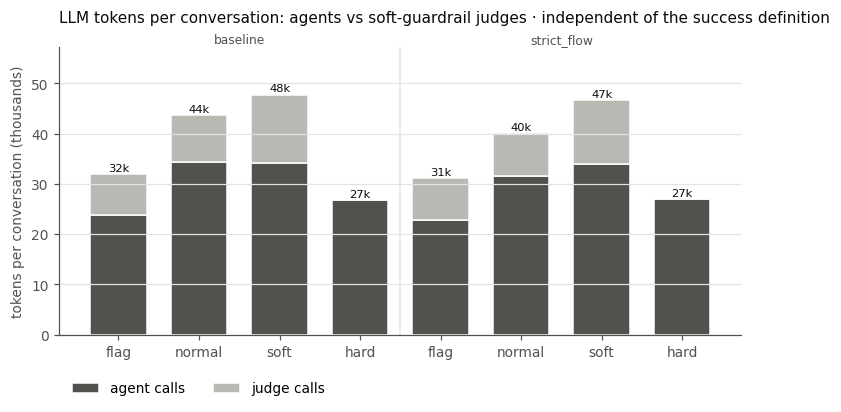

In [37]:
fig, ax = plt.subplots(figsize=(8, 3.4))
m = (
    conv.groupby(["family", "enforcement"])[["agent_tokens", "judge_tokens"]]
    .mean()
    .reindex(pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS]))
)
x = np.arange(len(m))
SHADES = {"agent_tokens": "#52514e", "judge_tokens": "#b9b8b2"}
bottom = np.zeros(len(m))
for col, label in [("agent_tokens", "agent calls"), ("judge_tokens", "judge calls")]:
    v = m[col].to_numpy() / 1000
    ax.bar(
        x,
        v,
        bottom=bottom,
        width=0.7,
        color=SHADES[col],
        edgecolor="white",
        linewidth=1,
        label=label,
    )
    bottom += v
for xi, total in zip(x, bottom):
    ax.annotate(
        f"{total:.0f}k",
        (xi, total),
        xytext=(0, 2),
        textcoords="offset points",
        ha="center",
        fontsize=7.5,
        color=INK,
    )
ax.set_ylim(0, bottom.max() * 1.2)
ax.set_xticks(x, [e for _ in FAMILIES for e in ENFORCEMENTS])
ax.axvline(len(ENFORCEMENTS) - 0.5, color=GRID, lw=1)
for k, fam in enumerate(FAMILIES):
    ax.annotate(
        fam,
        (k * len(ENFORCEMENTS) + 1.5, 1.0),
        xycoords=("data", "axes fraction"),
        ha="center",
        va="bottom",
        fontsize=8,
        color=MUTED,
    )
ax.set_ylabel("tokens per conversation (thousands)")
ax.set_title(
    f"LLM tokens per conversation: agents vs soft-guardrail judges · {LABEL_NONE}",
    loc="left",
    pad=16,
)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncols=2)
plt.show()

### 9.2 Cost vs `flag`, and hard vs soft

The same stratified mean difference as in Sections 7 and 8 (strata scenario × run, plus family for `both`). The first table compares each variant with `flag`. The second compares `hard` with `soft` directly. Use `cost_tokens` for the cost of enforcement against an unguarded system, and `agent_tokens` to see whether enforcement makes the agents themselves work more.

In [38]:
FMT_MEAN = (
    {c: "{:.2f}" for c in ["ref_mean", "mean"]}
    | {c: "{:+.2f}" for c in ["diff", "lo", "hi"]}
    | {"p": "{:.3f}", "p_holm": "{:.3f}"}
)
CMP_COLS = [
    "turns",
    "duration_min",
    "cost_tokens",
    "total_tokens",
    "judge_tokens",
    "agent_tokens",
]


def compare_measures(values, treatments, reference):
    out = pd.concat(
        [
            pooled_means_vs_reference(
                conv, v, treatments, reference=reference, groups=["family"]
            ).assign(measure=v)
            for v in values
        ]
        + [
            pooled_means_vs_reference(
                conv,
                v,
                treatments,
                reference=reference,
                groups=[],
                strata=["family", "scenario", "run"],
            ).assign(family="both", measure=v)
            for v in values
        ],
        ignore_index=True,
    )
    out["p_holm"] = rs.holm(out.p)
    return out[
        [
            "measure",
            "family",
            "enforcement",
            "vs",
            "ref_mean",
            "mean",
            "diff",
            "lo",
            "hi",
            "p",
            "p_holm",
        ]
    ]


compare_measures(CMP_COLS, TREATMENTS, "flag").style.format(FMT_MEAN).hide(axis="index")

measure,family,enforcement,vs,ref_mean,mean,diff,lo,hi,p,p_holm
turns,baseline,normal,flag,5.66,5.48,-0.18,-0.64,+0.28,0.446,1.000
turns,strict_flow,normal,flag,6.23,5.93,-0.30,-0.79,+0.19,0.230,1.000
turns,baseline,soft,flag,5.66,6.22,+0.56,-0.21,+1.33,0.153,1.000
turns,strict_flow,soft,flag,6.23,6.10,-0.13,-0.62,+0.36,0.593,1.000
turns,baseline,hard,flag,5.66,5.64,-0.02,-0.51,+0.47,0.936,1.000
turns,strict_flow,hard,flag,6.23,5.98,-0.25,-0.70,+0.20,0.269,1.000
duration_min,baseline,normal,flag,1.88,2.35,+0.47,+0.22,+0.71,0.000,0.005
duration_min,strict_flow,normal,flag,1.82,2.09,+0.27,+0.08,+0.47,0.007,0.119
duration_min,baseline,soft,flag,1.88,2.86,+0.98,+0.70,+1.25,0.000,0.000
duration_min,strict_flow,soft,flag,1.82,2.64,+0.82,+0.58,+1.07,0.000,0.000


In [39]:
compare_measures(
    CMP_COLS + ["checks", "denied", "violation_rate", "fallbacks"], ["hard"], "soft"
).style.format(FMT_MEAN).hide(axis="index")

measure,family,enforcement,vs,ref_mean,mean,diff,lo,hi,p,p_holm
turns,baseline,hard,soft,6.22,5.64,-0.58,-1.39,+0.23,0.158,0.475
turns,strict_flow,hard,soft,6.10,5.98,-0.12,-0.67,+0.43,0.668,0.668
duration_min,baseline,hard,soft,2.86,1.43,-1.42,-1.71,-1.14,0.000,0.000
duration_min,strict_flow,hard,soft,2.64,1.35,-1.30,-1.55,-1.04,0.000,0.000
cost_tokens,baseline,hard,soft,47792.08,26797.38,-20994.70,-26362.90,-15626.50,0.000,0.000
cost_tokens,strict_flow,hard,soft,46765.09,26948.03,-19817.07,-26683.44,-12950.70,0.000,0.000
total_tokens,baseline,hard,soft,47792.08,26797.38,-20994.70,-26362.90,-15626.50,0.000,0.000
total_tokens,strict_flow,hard,soft,46765.09,26948.03,-19817.07,-26683.44,-12950.70,0.000,0.000
judge_tokens,baseline,hard,soft,13621.11,0.00,-13621.11,-14963.66,-12278.55,0.000,0.000
judge_tokens,strict_flow,hard,soft,12878.93,0.00,-12878.93,-13812.93,-11944.92,0.000,0.000


### 9.3 Gateway decisions

The share of checks that ended in `allow`, `flag` or `deny`, split into tool calls and agent messages (the response gateway). In `flag` setups, `flag` marks a call that would have been denied. The exception would be `transfer:includes_order_id`, which only flags in every setup, but it never fired on its own in this data.

In [40]:
d = decisions.merge(conv[["thread_id", "family", "enforcement"]], on="thread_id")
shares = pd.crosstab([d.family, d.enforcement, d.kind], d.decision, normalize="index")[
    ["allow", "flag", "deny"]
]
shares["checks"] = d.groupby(["family", "enforcement", "kind"]).size()
shares.reindex(
    pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS, ["tool", "message"]])
).style.format("{:.1%}", subset=["allow", "flag", "deny"]).format(
    "{:,.0f}", subset=["checks"]
)

Which **type** of rule denied or flagged, per conversation. In `normal` setups both types block, so this shows which kind does the work in the mixed setup. In `soft` setups the hard flags come from the flag-only hard copies of the judged rules, and the few hard denies in `strict_flow_soft` come from the refund call limit.

In [41]:
v = (
    d[["thread_id", "family", "enforcement", "violations"]]
    .explode("violations")
    .dropna(subset=["violations"])
)
v = pd.concat(
    [
        v.drop(columns="violations").reset_index(drop=True),
        pd.json_normalize(v.violations.tolist()),
    ],
    axis=1,
)
per_conv = (
    v.groupby(["family", "enforcement", "type", "effect"]).size()
    / conv.groupby(["family", "enforcement"]).size()
)
per_conv.unstack(["type", "effect"], fill_value=0).reindex(
    pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS])
).fillna(0)

type                hard  soft  hard  soft
effect              flag  flag  deny  deny
baseline    flag   1.333 2.947 0.000 0.000
            normal 0.000 0.000 0.833 2.393
            soft   0.893 0.000 0.000 3.333
            hard   0.000 0.000 1.753 0.000
strict_flow flag   1.347 2.840 0.000 0.000
            normal 0.000 0.000 1.073 1.460
            soft   1.473 0.020 0.013 2.947
            hard   0.000 0.000 1.780 0.000

### 9.4 Relation to success

All tables and the figure in 9.4 use the **new** success definition; 9.5 repeats the key numbers with the old one.

**Cost of successful vs unsuccessful conversations.** These are descriptive, not causal: a failing conversation often runs longer because the agents retry.

In [42]:
conv.groupby(["enforcement", "success"])[
    ["turns", "duration_min", "cost_tokens", "denied", "flagged", "violation_rate"]
].mean().reindex(
    pd.MultiIndex.from_product([ENFORCEMENTS, [True, False]])
).style.format("{:.2f}").format("{:,.0f}", subset=["cost_tokens"])

**Success rate by number of interventions.** For enforcing setups the count is denies; for `flag` it is flags (calls that would have been denied). This shows whether conversations with more interventions end worse, and whether that differs between hard and soft. Compare within a row, not between rows: a deny makes the agent retry, and the retry can be denied again, so deny counts grow in a way flag counts don't.

In [43]:
conv["interventions"] = np.where(conv.enforcement == "flag", conv.flagged, conv.denied)
conv["intervention_bucket"] = pd.cut(
    conv.interventions, [-1, 0, 1, 3, np.inf], labels=["0", "1", "2-3", "4+"]
)
by_bucket = conv.groupby(
    ["enforcement", "intervention_bucket"], observed=False
).success.agg(rate="mean", n="count")
by_bucket.unstack("intervention_bucket").reindex(ENFORCEMENTS).style.format(
    "{:.0%}", subset=["rate"]
).format("{:.0f}", subset=["n"])

**Cost per success.** Cost tokens (see 9.1) and minutes spent per **successful** conversation (totals divided by the number of successes), per setup. A setup can be more successful and still cheaper per success, or more expensive per success when the judges' tokens outweigh what they gain.

In [44]:
eff = conv.groupby(["family", "enforcement"]).agg(
    success_rate=("success", "mean"),
    successes=("success", "sum"),
    tokens_per_conv=("cost_tokens", "mean"),
    tokens=("cost_tokens", "sum"),
    minutes=("duration_min", "sum"),
)
eff["tokens_per_success"] = eff.tokens / eff.successes
eff["minutes_per_success"] = eff.minutes / eff.successes
eff = eff.drop(columns=["tokens", "minutes"]).reindex(
    pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS])
)
eff.style.format(
    {
        "success_rate": "{:.0%}",
        "successes": "{:.0f}",
        "tokens_per_conv": "{:,.0f}",
        "tokens_per_success": "{:,.0f}",
        "minutes_per_success": "{:.1f}",
    }
)

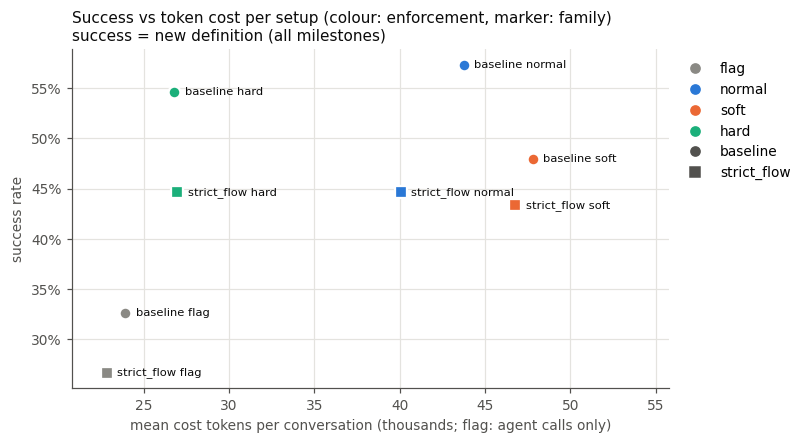

In [45]:
fig, ax = plt.subplots(figsize=(7, 4))
markers = {"baseline": "o", "strict_flow": "s"}
for (fam, e), r in eff.iterrows():
    ax.scatter(
        r.tokens_per_conv / 1000,
        r.success_rate,
        s=60,
        marker=markers[fam],
        color=COLORS[e],
        edgecolor="white",
        linewidth=1.5,
        zorder=3,
    )
    ax.annotate(
        f"{fam} {e}",
        (r.tokens_per_conv / 1000, r.success_rate),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=7.5,
        color=INK,
    )
x_k = eff.tokens_per_conv / 1000
ax.set_xlim(x_k.min() - 2, x_k.max() + 8)
ax.set_xlabel("mean cost tokens per conversation (thousands; flag: agent calls only)")
ax.set_ylabel("success rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="x", color=GRID)
ax.set_title(
    f"Success vs token cost per setup (colour: enforcement, marker: family)\n{LABEL_NEW}",
    loc="left",
)
handles = [
    plt.Line2D([], [], marker="o", ls="", color=COLORS[e], label=e)
    for e in ENFORCEMENTS
]
handles += [
    plt.Line2D([], [], marker=markers[f], ls="", color=MUTED, label=f) for f in FAMILIES
]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

### 9.5 Overall effect vs `flag`, under both success definitions

This subsection asks the general question: **do guardrails change outcomes and cost compared with no enforcement?** It pools over scenarios, and over families for the `both` rows. `enforced` pools `normal`, `soft` and `hard`.

It uses both success definitions, so the conclusion doesn't rest on one choice:

- **`success_v1`:** anything that went through ended up on the tray, or a refund was made (the earlier definition).
- **`success`:** every milestone was reached (Section 2).

For each variant and definition:

- `Δ success`: the difference in success rate vs `flag`, in percentage points.
- `tokens/conv ×`: the variant's mean cost tokens per conversation divided by `flag`'s. For `flag`, cost tokens are the agents' tokens only (see 9.1): the comparison is with what an unguarded system would pay.
- `tokens/success ×`: cost tokens divided by the number of successful conversations, as a ratio to `flag`. Below 1 means a success costs fewer tokens than without enforcement.

Intervals are 95% percentile bootstrap intervals. Conversations are resampled within each family × scenario × run × variant cell, so the scenario mix stays fixed.

In [46]:
GROUPS_FAM = {
    "baseline": ["baseline"],
    "strict_flow": ["strict_flow"],
    "both": FAMILIES,
}
GROUPS_ENF = {
    "normal": ["normal"],
    "soft": ["soft"],
    "hard": ["hard"],
    "enforced": TREATMENTS,
    "flag": ["flag"],
}
CRITERIA = {"success_v1": "old: anything delivered", "success": "new: all milestones"}


def efficiency_bootstrap(df, success_cols, reps=2000, seed=0):
    """Success rate, tokens per conversation and tokens per success per family group x
    enforcement group, relative to flag; point estimates plus percentile intervals."""
    rng = np.random.default_rng(seed)
    strata = list(
        df.groupby(["family", "scenario", "run", "enforcement"]).indices.items()
    )
    values = np.column_stack(
        [np.ones(len(df)), df.cost_tokens.to_numpy(float)]
        + [df[c].to_numpy(float) for c in success_cols]
    )

    def cell_sums(draw):
        out = {}
        for (fam, _, _, enf), idx in strata:
            out[(fam, enf)] = out.get((fam, enf), 0) + values[draw(idx)].sum(axis=0)
        return out

    def metrics(s):
        agg = {
            (fg, eg): sum(s[(f, e)] for f in fams for e in enfs)
            for fg, fams in GROUPS_FAM.items()
            for eg, enfs in GROUPS_ENF.items()
        }
        res = {}
        for (fg, eg), a in agg.items():
            ref = agg[(fg, "flag")]
            res[(fg, eg, "tokens/conv ×")] = (a[1] / a[0]) / (ref[1] / ref[0])
            for k, c in enumerate(success_cols, start=2):
                res[(fg, eg, f"{c}: rate")] = a[k] / a[0]
                res[(fg, eg, f"{c}: Δ success")] = a[k] / a[0] - ref[k] / ref[0]
                res[(fg, eg, f"{c}: tokens/success")] = a[1] / a[k] if a[k] else np.nan
                res[(fg, eg, f"{c}: tokens/success ×")] = (
                    (a[1] / a[k]) / (ref[1] / ref[k]) if a[k] and ref[k] else np.nan
                )
        return res

    point = metrics(cell_sums(lambda idx: idx))
    keys = list(point)
    draws = np.array(
        [
            [m[k] for k in keys]
            for m in (
                metrics(cell_sums(lambda idx: rng.choice(idx, size=len(idx))))
                for _ in range(reps)
            )
        ]
    )
    lo, hi = np.nanpercentile(draws, [2.5, 97.5], axis=0)
    return pd.DataFrame(
        {"estimate": [point[k] for k in keys], "lo": lo, "hi": hi},
        index=pd.MultiIndex.from_tuples(
            keys, names=["family", "enforcement", "metric"]
        ),
    )


overall = efficiency_bootstrap(conv, list(CRITERIA))

In [47]:
def overall_table(family):
    t = overall.xs(family, level="family")
    rows = []
    for enf in ["flag", *TREATMENTS, "enforced"]:
        r = {
            "enforcement": enf,
            "cost tokens/conv": conv.loc[
                conv.enforcement.isin(GROUPS_ENF[enf])
                & conv.family.isin(GROUPS_FAM[family]),
                "cost_tokens",
            ].mean(),
        }
        if enf != "flag":
            e, lo, hi = t.loc[(enf, "tokens/conv ×")]
            r["cost tokens/conv ×"] = f"{e:.2f} [{lo:.2f}, {hi:.2f}]"
        for c, label in CRITERIA.items():
            r[(label, "rate")] = f"{t.loc[(enf, f'{c}: rate'), 'estimate']:.0%}"
            r[(label, "tokens/success")] = (
                f"{t.loc[(enf, f'{c}: tokens/success'), 'estimate']:,.0f}"
            )
            if enf != "flag":
                e, lo, hi = t.loc[(enf, f"{c}: Δ success")]
                r[(label, "Δ success")] = f"{e:+.0%} [{lo:+.0%}, {hi:+.0%}]"
                e, lo, hi = t.loc[(enf, f"{c}: tokens/success ×")]
                r[(label, "tokens/success ×")] = f"{e:.2f} [{lo:.2f}, {hi:.2f}]"
        rows.append(r)
    out = pd.DataFrame(rows).set_index("enforcement").fillna("–")
    out.columns = pd.MultiIndex.from_tuples(
        [c if isinstance(c, tuple) else ("cost", c) for c in out.columns]
    )
    out[("cost", "cost tokens/conv")] = out[("cost", "cost tokens/conv")].map(
        lambda v: f"{v:,.0f}"
    )
    order = [("cost", "cost tokens/conv"), ("cost", "cost tokens/conv ×")] + [
        (label, m)
        for label in CRITERIA.values()
        for m in ["rate", "Δ success", "tokens/success", "tokens/success ×"]
    ]
    return out[order]


for family in ["both", *FAMILIES]:
    print(f"\n{family}")
    display(overall_table(family))


both


cost                    old: anything delivered  \
            cost tokens/conv cost tokens/conv ×                    rate   
enforcement                                                               
flag                  23,360                  –                     56%   
normal                41,903  1.79 [1.63, 1.98]                     58%   
soft                  47,279  2.02 [1.86, 2.22]                     56%   
hard                  26,873  1.15 [1.06, 1.26]                     57%   
enforced              38,685  1.66 [1.56, 1.76]                     57%   

                                                               \
                  Δ success tokens/success   tokens/success ×   
enforcement                                                     
flag                      –         41,963                  –   
normal       +3% [-4%, +9%]         71,834  1.71 [1.47, 2.00]   
soft         +0% [-7%, +7%]         84,426  2.01 [1.73, 2.34]   
hard         +1% [-6%, +8%]         47,422  1.13 [0.98, 1.31]   
enforced     +1% [-4%, +7%]         67,868  1.62 [1.45, 1.81]   

            new: all milestones                                    \
                           rate          Δ success tokens/success   
enforcement                                                         
flag                        30%                  –         78,740   
normal                      51%  +21% [+15%, +28%]         82,163   
soft                        46%   +16% [+9%, +23%]        103,530   
hard                        50%  +20% [+13%, +27%]         54,106   
enforced                    49%  +19% [+14%, +24%]         79,308   

                                
              tokens/success ×  
enforcement                     
flag                         –  
normal       1.04 [0.85, 1.27]  
soft         1.31 [1.07, 1.62]  
hard         0.69 [0.56, 0.83]  
enforced     1.01 [0.85, 1.17]


baseline


cost                    old: anything delivered  \
            cost tokens/conv cost tokens/conv ×                    rate   
enforcement                                                               
flag                  23,901                  –                     62%   
normal                43,753  1.83 [1.61, 2.10]                     67%   
soft                  47,792  2.00 [1.77, 2.26]                     58%   
hard                  26,797  1.12 [1.02, 1.23]                     61%   
enforced              39,447  1.65 [1.51, 1.80]                     62%   

                                                                \
                   Δ success tokens/success   tokens/success ×   
enforcement                                                      
flag                       –         38,551                  –   
normal       +5% [-5%, +14%]         65,629  1.70 [1.38, 2.10]   
soft         -4% [-13%, +5%]         82,400  2.14 [1.75, 2.61]   
hard         -1% [-10%, +8%]         43,691  1.13 [0.95, 1.36]   
enforced      +0% [-8%, +8%]         63,625  1.65 [1.43, 1.92]   

            new: all milestones                                    \
                           rate          Δ success tokens/success   
enforcement                                                         
flag                        33%                  –         73,167   
normal                      57%  +25% [+15%, +33%]         76,313   
soft                        48%   +15% [+7%, +24%]         99,567   
hard                        55%  +22% [+13%, +31%]         49,020   
enforced                    53%  +21% [+14%, +27%]         73,964   

                                
              tokens/success ×  
enforcement                     
flag                         –  
normal       1.04 [0.82, 1.35]  
soft         1.36 [1.03, 1.78]  
hard         0.67 [0.53, 0.86]  
enforced     1.01 [0.82, 1.23]


strict_flow


cost                    old: anything delivered  \
            cost tokens/conv cost tokens/conv ×                    rate   
enforcement                                                               
flag                  22,818                  –                     49%   
normal                40,053  1.76 [1.52, 2.03]                     50%   
soft                  46,765  2.05 [1.81, 2.33]                     54%   
hard                  26,948  1.18 [1.03, 1.35]                     52%   
enforced              37,922  1.66 [1.52, 1.83]                     52%   

                                                                \
                   Δ success tokens/success   tokens/success ×   
enforcement                                                      
flag                       –         46,252                  –   
normal       +1% [-9%, +11%]         80,106  1.73 [1.34, 2.23]   
soft         +5% [-6%, +15%]         86,602  1.87 [1.46, 2.36]   
hard         +3% [-7%, +13%]         51,823  1.12 [0.88, 1.42]   
enforced     +3% [-6%, +11%]         72,927  1.58 [1.30, 1.88]   

            new: all milestones                                    \
                           rate          Δ success tokens/success   
enforcement                                                         
flag                        27%                  –         85,566   
normal                      45%   +18% [+9%, +27%]         89,671   
soft                        43%   +17% [+7%, +26%]        107,919   
hard                        45%   +18% [+8%, +28%]         60,331   
enforced                    44%  +18% [+10%, +25%]         85,753   

                                
              tokens/success ×  
enforcement                     
flag                         –  
normal       1.05 [0.75, 1.42]  
soft         1.26 [0.91, 1.74]  
hard         0.71 [0.51, 0.96]  
enforced     1.00 [0.76, 1.28]

The same results as a picture: success rate against mean cost tokens per conversation, per family and variant. The two panels share their axes; the dashed lines connect each family's `flag` point to its enforcing variants.

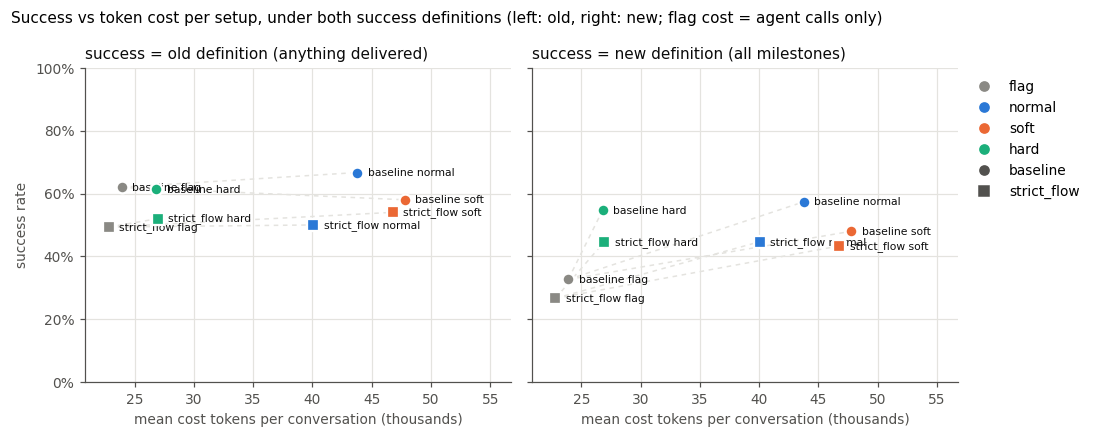

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
markers = {"baseline": "o", "strict_flow": "s"}
for ax, (c, label) in zip(axes, CRITERIA.items()):
    for fam in FAMILIES:
        ref = overall.loc[(fam, "flag", f"{c}: rate"), "estimate"]
        ref_x = (
            conv.loc[
                (conv.family == fam) & (conv.enforcement == "flag"), "cost_tokens"
            ].mean()
            / 1000
        )
        for e in ENFORCEMENTS:
            y = overall.loc[(fam, e, f"{c}: rate"), "estimate"]
            x = (
                conv.loc[
                    (conv.family == fam) & (conv.enforcement == e), "cost_tokens"
                ].mean()
                / 1000
            )
            if e != "flag":
                ax.plot(
                    [ref_x, x], [ref, y], color=GRID, lw=1, ls=(0, (3, 3)), zorder=1
                )
            ax.scatter(
                x,
                y,
                s=60,
                marker=markers[fam],
                color=COLORS[e],
                edgecolor="white",
                linewidth=1.5,
                zorder=3,
            )
            ax.annotate(
                f"{fam} {e}",
                (x, y),
                xytext=(7, 0),
                textcoords="offset points",
                va="center",
                fontsize=7,
                color=INK,
            )
    ax.set_title({"success_v1": LABEL_OLD, "success": LABEL_NEW}[c], loc="left")
    ax.set_xlabel("mean cost tokens per conversation (thousands)")
    ax.grid(axis="x", color=GRID)
axes[0].set_ylabel("success rate")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylim(0, 1)
x_all = conv.groupby(["family", "enforcement"]).cost_tokens.mean() / 1000
axes[0].set_xlim(x_all.min() - 2, x_all.max() + 9)
handles = [
    plt.Line2D([], [], marker="o", ls="", color=COLORS[e], label=e)
    for e in ENFORCEMENTS
]
handles += [
    plt.Line2D([], [], marker=markers[f], ls="", color=MUTED, label=f) for f in FAMILIES
]
axes[1].legend(handles=handles, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.suptitle(
    "Success vs token cost per setup, under both success definitions (left: old, right: new; flag cost = agent calls only)",
    x=0.01,
    ha="left",
    fontsize=10,
)
fig.tight_layout()
plt.show()

**Success by number of interventions, old definition.** This is the same table as in 9.4, but with `success_v1`, to check that the pattern (violations hurt without enforcement, while a few denies don't) doesn't depend on the success definition.

In [49]:
conv.groupby(["enforcement", "intervention_bucket"], observed=False).success_v1.agg(
    rate="mean", n="count"
).unstack("intervention_bucket").reindex(ENFORCEMENTS).style.format(
    "{:.0%}", subset=["rate"]
).format("{:.0f}", subset=["n"])

## 10. Run-to-run consistency

The runs use the same code, model and machine seed, so any difference between them is noise from the LLMs. Sections 3–9 pool them; this section checks that pooling is justified. Both parts use the **new** success definition and work for any number of runs.

### 10.1 Success rate per cell and run

The rate of each setup × scenario cell in each run, the spread between the runs (highest − lowest rate) and a test of whether the runs share one rate (Monte Carlo exact conditional test, Holm over the 24 cells). The runs have different sizes per cell, so the spread alone overstates the noise of a small run: with 9 conversations a rate moves in steps of 11 points. A cell whose rate differs between runs more than chance allows (`p_holm` < 0.05) would argue against pooling it.

In [50]:
run_names = list(runs.run)
if len(run_names) >= 2:
    cell_keys = ["family", "enforcement", "scenario"]
    per_run = rates(conv, cell_keys + ["run"])
    rows = []
    for key, g in per_run.groupby(cell_keys):
        g = g.set_index("run").reindex(run_names)
        rows.append(
            {
                **dict(zip(cell_keys, key)),
                **g.rate.to_dict(),
                "spread": g.rate.max() - g.rate.min(),
                "p": rs.homogeneity_p(g.k, g.n),
            }
        )
    consistency = pd.DataFrame(rows)
    consistency["p_holm"] = rs.holm(consistency.p)
    consistency = consistency.set_index(cell_keys).reindex(
        pd.MultiIndex.from_product([FAMILIES, ENFORCEMENTS, list(SCENARIOS)])
    )
    n_per_run = ", ".join(f"{r} {n}" for r, n in runs.set_index("run").per_cell.items())
    print(
        f"{len(run_names)} runs (per cell: {n_per_run}). Spread between runs: "
        f"median {consistency.spread.median():.0%}, max {consistency.spread.max():.0%}. "
        f"Cells with p_holm < 0.05: {(consistency.p_holm < 0.05).sum()} of {len(consistency)}."
    )
    display(
        consistency.style.format("{:.0%}", subset=run_names + ["spread"]).format(
            "{:.3f}", subset=["p", "p_holm"]
        )
    )

3 runs (per cell: mini 9, more 16, run3 25). Spread between runs: median 26%, max 38%. Cells with p_holm < 0.05: 0 of 24.


### 10.2 Effect of enforcement per run

The pooled comparison of Section 5 (each variant vs `flag`, Mantel-Haenszel risk difference), estimated **separately in each run** with strata family × scenario. If the effects agree between runs, the pooled estimate summarises them fairly. `p_heterogeneity` is Cochran's Q test that the per-run effects are equal; a small value means the effect depends on the run, and the pooled estimate should be read with care.

In [51]:
if len(run_names) >= 2:
    by_run = pooled_vs_reference(
        conv, TREATMENTS, groups=["run"], strata=["family", "scenario"]
    )
    display(
        by_run.set_index(["enforcement", "run"])
        .reindex(pd.MultiIndex.from_product([TREATMENTS, run_names]))[
            ["rate", "ref_rate", "rd", "lo", "hi", "p_cmh", "n", "n_ref"]
        ]
        .style.format("{:.0%}", subset=["rate", "ref_rate"])
        .format("{:+.0%}", subset=["rd", "lo", "hi"])
        .format("{:.3f}", subset=["p_cmh"])
    )
    heterogeneity = (
        pd.DataFrame(
            [
                {
                    "enforcement": t,
                    **g.set_index("run").rd.reindex(run_names).to_dict(),
                    "p_heterogeneity": rs.cochran_q_p(
                        g.rd, (g.hi - g.lo) / (2 * rs.Z95)
                    ),
                }
                for t, g in by_run.groupby("enforcement")
            ]
        )
        .set_index("enforcement")
        .reindex(TREATMENTS)
    )
    display(
        heterogeneity.style.format("{:+.0%}", subset=run_names).format(
            "{:.3f}", subset=["p_heterogeneity"]
        )
    )

,mini,more,run3,p_heterogeneity
enforcement,,,,
normal,+20%,+22%,+21%,0.989
soft,+6%,+28%,+12%,0.074
hard,+20%,+25%,+17%,0.613


## 11. Distribution figures

Box plots of conversation length and token cost per conversation, per setup and per setup × scenario. Every figure is also saved to `analysis/figures/`.

- **Messages** (`messages`): the customer's messages plus agent messages with visible text, counted in the conversation's final message history (tool calls, tool results and the guardrails' internal notes are not messages).
- **Tokens** (`cost_tokens`, see 9.1): agents and enforcing judges; the `flag` setups count only the agents.

The x-axis is capped so a few very long conversations don't squeeze the rest; conversations beyond the cap are counted at the right edge, and the median printed on the right includes them. These figures are descriptive; the tests are in Sections 9.1–9.2.

In [52]:
import textwrap

FIGURES_DIR = ANALYSIS_DIR / "figures"
SURFACE = "#fcfcfb"
FIGURE_STYLE = {
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.edgecolor": MUTED,
    "axes.labelcolor": MUTED,
    "axes.titlecolor": INK,
    "xtick.color": MUTED,
    "ytick.color": INK,
    "ytick.left": False,
    "axes.grid": True,
    "axes.grid.axis": "x",
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "font.size": 9,
    "legend.frameon": False,
}
MEASURES = {
    "messages": dict(
        column="messages",
        scale=1,
        xmax=40,
        step=5,
        unit="",
        axis="messages per conversation",
        title="Messages per conversation",
        stem="messages_per_conversation",
        definition="Messages = customer messages + agent messages with visible text "
        "(tool calls, tool results and guardrail notes excluded).",
    ),
    "tokens": dict(
        column="cost_tokens",
        scale=1000,
        xmax=120,
        step=20,
        unit="k",
        axis="thousand tokens per conversation",
        title="Token consumption per conversation",
        stem="tokens_per_conversation",
        definition="Tokens = input + output tokens of the LLM calls inside the conversation: "
        "the agents' calls plus the soft-guardrail judge calls that enforce rules (hard rules "
        "use none). The flag setups count the agents' calls only: their judges just observe "
        "and would not run in an unguarded system. The customer simulator and the feedback "
        "rating are not included.",
    ),
}
BOX_READING = (
    "Box = interquartile range, black line = median, whiskers = furthest conversation "
    "within 1.5 IQR, dots = conversations beyond."
)
# One row per setup; a blank row between the families.
ROW_Y = {
    (f, e): i + fi
    for fi, f in enumerate(FAMILIES)
    for i, e in enumerate(ENFORCEMENTS, start=fi * len(ENFORCEMENTS))
}


def setup_label(family, enforcement):
    return family if enforcement == "normal" else f"{family}_{enforcement}"


def _draw_box(ax, x, y, color):
    b = ax.boxplot(
        [x],
        positions=[y],
        orientation="horizontal",
        widths=0.55,
        whis=1.5,
        patch_artist=True,
        manage_ticks=False,
        boxprops=dict(facecolor=color, alpha=0.35, edgecolor=color, linewidth=1),
        medianprops=dict(color=INK, linewidth=2, solid_capstyle="butt"),
        whiskerprops=dict(color=color, linewidth=1),
        capprops=dict(color=color, linewidth=1),
        flierprops=dict(
            marker="o",
            markersize=2.5,
            markerfacecolor=color,
            markeredgewidth=0,
            alpha=0.5,
        ),
    )
    for artist in b["boxes"] + b["medians"] + b["whiskers"] + b["caps"] + b["fliers"]:
        artist.set_zorder(3)
    return float(np.median(x))


def _draw_panel(ax, data, m):
    unit, xmax = m["unit"], m["xmax"]
    values = data[m["column"]] / m["scale"]
    for (family, enf), y in ROW_Y.items():
        x = values[(data.family == family) & (data.enforcement == enf)].to_numpy(float)
        if not len(x):
            continue
        median = _draw_box(ax, x, y, COLORS[enf])
        over = int((x > xmax).sum())
        if over:
            ax.scatter(
                [xmax * 0.9875], [y], marker=">", s=22, color=COLORS[enf], zorder=5
            )
            ax.text(
                xmax * 0.995,
                y - 0.2,
                f"{over} > {xmax}{unit}",
                ha="right",
                va="bottom",
                fontsize=6.5,
                color=MUTED,
                zorder=5,
            )
        label = f"{median:.1f}" if unit else f"{median:g}"
        ax.text(
            1.02,
            y,
            label + unit,
            transform=ax.get_yaxis_transform(),
            ha="left",
            va="center",
            fontsize=8,
            color=INK,
        )
    ax.set_yticks(list(ROW_Y.values()), [setup_label(*r) for r in ROW_Y])
    ax.set_ylim(max(ROW_Y.values()) + 0.7, -1.1)
    ax.set_xlim(0, xmax)
    ax.xaxis.set_major_locator(plt.MultipleLocator(m["step"]))
    ax.text(
        1.02,
        -1.05,
        "median",
        transform=ax.get_yaxis_transform(),
        ha="left",
        va="bottom",
        fontsize=7.5,
        color=MUTED,
    )
    ax.set_xlabel(m["axis"])


def _legend(fig):
    handles = [
        plt.Line2D(
            [],
            [],
            marker="o",
            ls="",
            markersize=7,
            color=COLORS[e],
            markeredgecolor=SURFACE,
            markeredgewidth=1.5,
        )
        for e in ENFORCEMENTS
    ]
    labels = list(ENFORCEMENTS)
    fig.legend(
        handles,
        labels,
        loc="upper left",
        ncols=len(labels),
        bbox_to_anchor=(0.012, 0.885),
        handletextpad=0.5,
        columnspacing=1.4,
        labelcolor=MUTED,
        fontsize=8.5,
    )


def _note(fig, m, width, y):
    xmax, unit = m["xmax"], m["unit"]
    over = f"more than {xmax}{unit} tokens" if unit else f"more than {xmax} messages"
    per_cell = " + ".join(str(n) for n in runs.per_cell)
    provenance = (
        f"Runs {' + '.join(runs.run)} ({per_cell} conversations per setup and scenario), "
        f"commit {', '.join(runs.commit.unique())}, {', '.join(runs.model.unique())}."
    )
    text = (
        f"{m['definition']} {BOX_READING} Conversations with {over} are counted at the "
        f"right edge; the median includes them. {provenance}"
    )
    fig.text(
        0.02,
        y,
        "\n".join(textwrap.wrap(text, width)),
        fontsize=6.5,
        color=MUTED,
        va="top",
    )


def distribution_figure(measure, by_scenario):
    """Draw one box-plot figure and save it to FIGURES_DIR; returns the figure."""
    m = MEASURES[measure]
    n_setup = conv.groupby("setup").size()
    n_cell = conv.groupby(["setup", "scenario"]).size()
    with plt.rc_context(FIGURE_STYLE):
        if by_scenario:
            fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(11, 5.0), sharey=True)
            for i, (ax, (scenario, name)) in enumerate(zip(axes, SCENARIOS.items())):
                _draw_panel(ax, conv[conv.scenario == scenario], m)
                ax.set_title(name, loc="left", fontsize=9.5, pad=14)
                ax.tick_params(labelleft=(i == 0))
            title = f"{m['title']}, by setup and scenario"
            subtitle = (
                f"{n_cell.min()} conversations per setup and scenario"
                if n_cell.min() == n_cell.max()
                else f"{n_cell.min()}–{n_cell.max()} conversations per setup and scenario"
            )
            _note(fig, m, width=220, y=0.095)
            fig.subplots_adjust(
                left=0.12, right=0.955, top=0.74, bottom=0.23, wspace=0.2
            )
            name = f"{m['stem']}_by_setup_and_scenario_box.png"
        else:
            fig, ax = plt.subplots(figsize=(7.6, 5.7))
            _draw_panel(ax, conv, m)
            title = f"{m['title']}, by setup"
            subtitle = (
                f"{n_setup.min()} conversations per setup ({n_cell.min()} per scenario)"
                if n_setup.min() == n_setup.max()
                else f"{n_setup.min()}–{n_setup.max()} conversations per setup"
            )
            _note(fig, m, width=148, y=0.115)
            fig.subplots_adjust(left=0.19, right=0.91, top=0.8, bottom=0.25)
            name = f"{m['stem']}_by_setup_box.png"
        fig.suptitle(title, x=0.02, ha="left", fontsize=11, color=INK, y=0.975)
        fig.text(0.02, 0.9, subtitle, fontsize=9, color=MUTED)
        _legend(fig)
        FIGURES_DIR.mkdir(exist_ok=True)
        fig.savefig(FIGURES_DIR / name, dpi=200)
    return fig

### 11.1 Messages per conversation

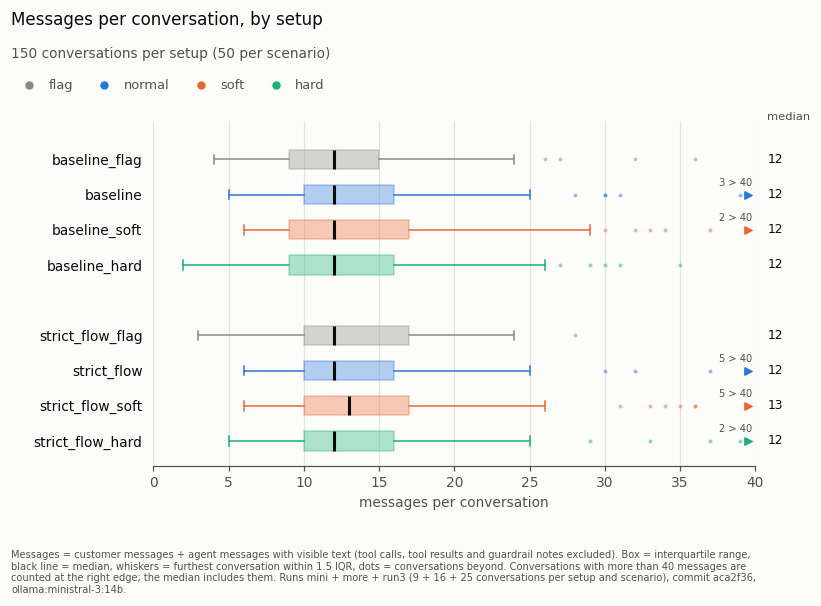

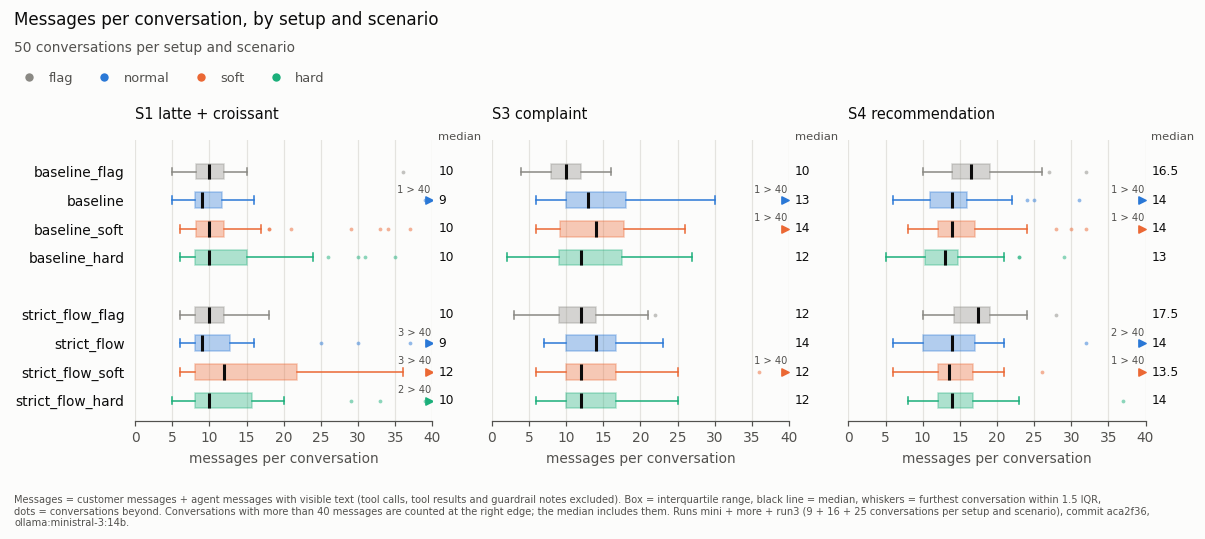

In [53]:
for by_scenario in (False, True):
    distribution_figure("messages", by_scenario)
    plt.show()

### 11.2 Token consumption per conversation

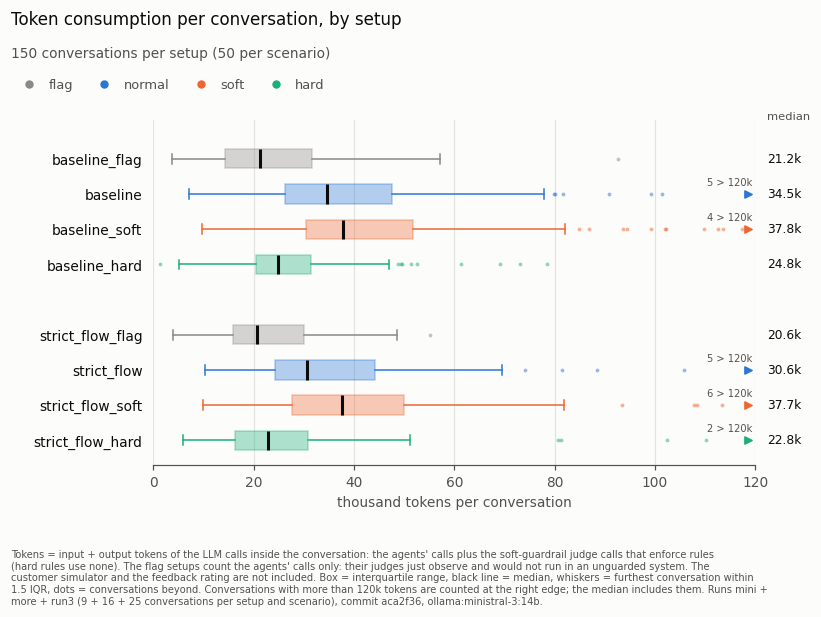

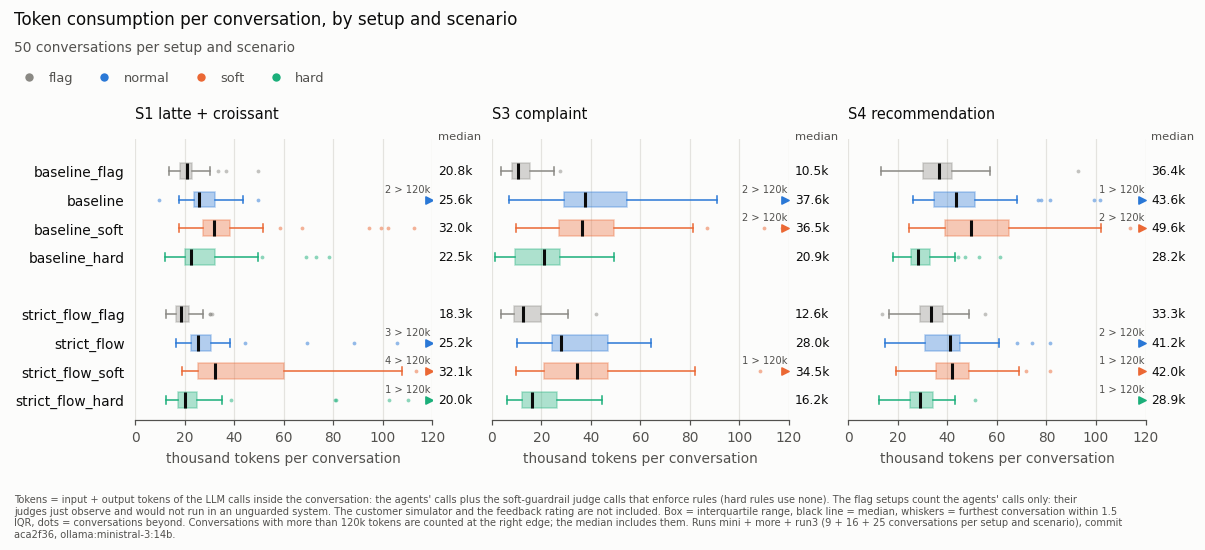

In [54]:
for by_scenario in (False, True):
    distribution_figure("tokens", by_scenario)
    plt.show()

## 12. Next analyses

The per-conversation table `conv` (one row per conversation, with `success`, `progress`, the milestone flags and the call counts), `milestones` (one row per conversation and milestone), `calls` (executed tool calls) and `gateway` (gateway decisions) are the starting point for the next sections. Planned:

- Customer feedback vs actual success (high feedback without success, i.e. hallucinated completions)
- Guardrail activity per rule: denies and flags per setup, and how often a deny leads to a fallback
- Per-rule view of Section 9: which rules drive the denies, and how often a deny is followed by success
- Process view: how enforcement changes the order lifecycle paths